# ADHD Diagnosis Prediction — WiDS Datathon 2025

End-to-end ML pipeline: data loading → EDA → feature engineering → model comparison → SHAP interpretation.

In [1]:
# Install required packages (run once)
!pip install lightgbm xgboost imbalanced-learn shap -q

^C


ERROR: Could not install packages due to an OSError: [WinError 32] The process cannot access the file because it is being used by another process: 'C:\\Users\\BOSS\\AppData\\Local\\Temp\\pip-unpack-ci7baoc6\\numpy-2.1.3-cp313-cp313-win_amd64.whl'
Consider using the `--user` option or check the permissions.



In [6]:
!pip install imbalanced-learn --quiet

  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
mlxtend 0.24.0 requires numpy>=2.3.5, but you have numpy 2.1.3 which is incompatible.
mlxtend 0.24.0 requires scikit-learn>=1.8.0, but you have scikit-learn 1.6.1 which is incompatible.


In [6]:
!pip install "numpy<2.2" "numba>=0.60" --quiet

In [2]:
import numpy
print(numpy.__version__)   

2.1.3


In [2]:
!pip install --upgrade numexpr


  Attempting uninstall: numexpr
    Found existing installation: numexpr 2.10.1
    Uninstalling numexpr-2.10.1:
      Successfully uninstalled numexpr-2.10.1


In [3]:
import numexpr
print(numexpr.__version__)

2.10.1


In [1]:
# ─── Standard library ───────────────────────────────────────────
import os, time, warnings
from datetime import datetime

# ─── Data / Math ─────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from scipy import stats

# ─── Scikit-learn ────────────────────────────────────────────────
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, PowerTransformer, OrdinalEncoder  # FIX: OrdinalEncoder replaces LabelEncoder
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_val_score, RandomizedSearchCV)  # FIX: RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,  # FIX: GradientBoosting added
                              AdaBoostClassifier, StackingClassifier)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans  # single import, not re-imported inside functions
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve,
                             precision_recall_curve, auc)
from sklearn.inspection import PartialDependenceDisplay

# ─── Boosting libraries ──────────────────────────────────────────
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier



In [2]:
# ─── Class-imbalance handling ────────────────────────────────────
try:
    from imblearn.over_sampling import SMOTE
    SMOTE_AVAILABLE = True
    print("SMOTE available.")
except ImportError:
    SMOTE_AVAILABLE = False
    print("imbalanced-learn not found; SMOTE will be skipped. Run: pip install imbalanced-learn")

# ─── Global settings ─────────────────────────────────────────────
warnings.filterwarnings('ignore')
os.makedirs('plots', exist_ok=True)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# FIX: safe style fallback for different matplotlib/seaborn versions
try:
    plt.style.use('seaborn-v0_8-whitegrid')
except OSError:
    try:
        plt.style.use('seaborn-whitegrid')
    except OSError:
        pass  # use matplotlib default

sns.set_palette("viridis")
print("All imports successful.")

SMOTE available.
All imports successful.


In [3]:
# ─────────────────────────────────────────────────────────────────
# Environment detection: runs in both Google Colab and local
# ─────────────────────────────────────────────────────────────────
import sys
IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # FIX: import files for Colab downloads
    from google.colab import drive, files
    drive.mount('/content/drive', force_remount=True)
    BASE_PATH = '/content/drive/MyDrive/widsdatathon2025'  # ← update to your Drive folder
else:
    BASE_PATH = r'widsdatathon2025'  # ← update to your local path

print(f"Environment: {'Google Colab' if IN_COLAB else 'Local'}")
print(f"Base path: {BASE_PATH}")


def load_data(base_path=BASE_PATH):
    """Load and merge all WiDS 2025 dataset files."""

    def p(*parts):
        return os.path.join(base_path, *parts)

    # ── Training files ──────────────────────────────────────────
    target     = pd.read_excel(p('TRAIN_NEW', 'TRAINING_SOLUTIONS.xlsx'))
    t2         = pd.read_csv(p('TRAIN_NEW', 'TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv'))
    train_cat  = pd.read_excel(p('TRAIN_NEW', 'TRAIN_CATEGORICAL_METADATA_new.xlsx'))
    train_quant= pd.read_excel(p('TRAIN_NEW', 'TRAIN_QUANTITATIVE_METADATA_new.xlsx'))

    train = (train_cat
             .merge(train_quant, on='participant_id')
             .merge(target,      on='participant_id')
             .merge(t2,          on='participant_id'))
    train['data_source'] = 'train'

    # ── Test files ──────────────────────────────────────────────
    t3         = pd.read_csv(p('TEST', 'TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv'))
    test_cat   = pd.read_excel(p('TEST', 'TEST_CATEGORICAL.xlsx'))
    test_quant = pd.read_excel(p('TEST', 'TEST_QUANTITATIVE_METADATA.xlsx'))

    test = (test_cat
            .merge(test_quant, on='participant_id')
            .merge(t3,         on='participant_id'))
    test['data_source'] = 'test'

    return train, test


# FIX: removed no-op try/except; a real error here should surface immediately
train, test = load_data()
print(f"Train shape: {train.shape}")
print(f"Test  shape: {test.shape}")

Environment: Local
Base path: widsdatathon2025
Train shape: (1213, 19931)
Test  shape: (304, 19929)


In [4]:
# ─── Quick data exploration ──────────────────────────────────────
print("=== TRAIN HEAD ===")
display(train.head())
print(f"\nRows: {train.shape[0]:,}  |  Columns: {train.shape[1]:,}")
print(f"\nData types:\n{train.dtypes.value_counts()}")
print(f"\nTarget distribution:\n{train['ADHD_Outcome'].value_counts()}")
missing = train.isnull().sum()
print(f"\nColumns with missing values: {(missing > 0).sum()}")
print(missing[missing > 0].sort_values(ascending=False).head(10))

=== TRAIN HEAD ===


,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,195throw_197thcolumn,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn,data_source
0,00aIpNTbG5uh,2019,4,1.0,0.0,3.0,21.0,45.0,NaN,NaN,...,-0.096450,-0.280312,0.037560,0.423037,0.242453,0.336213,0.402338,0.327915,0.539032,train
1,00fV0OyyoLfw,2017,1,0.0,9.0,2.0,21.0,0.0,21.0,45.0,...,-0.276464,-0.332783,-0.332711,0.556939,0.475578,0.429196,0.457970,0.312571,0.595978,train
2,04X1eiS79T4B,2017,1,1.0,2.0,2.0,9.0,0.0,NaN,NaN,...,-0.108588,-0.002132,-0.175586,0.679183,0.290292,0.486680,0.255208,0.575017,0.605182,train
3,05ocQutkURd6,2018,1,3.0,8.0,2.0,18.0,10.0,18.0,0.0,...,-0.041420,-0.199576,-0.216457,0.519074,0.298586,0.415466,0.511607,0.361204,0.446613,train
4,06YUNBA9ZRLq,2018,1,0.0,1.0,2.0,12.0,0.0,NaN,NaN,...,-0.274017,-0.141012,-0.002865,0.515169,0.336139,0.316430,0.442230,0.177079,0.378278,train



Rows: 1,213  |  Columns: 19,931

Data types:
float64    19925
int64          4
str            2
Name: count, dtype: int64

Target distribution:
ADHD_Outcome
1    831
0    382
Name: count, dtype: int64

Columns with missing values: 25
MRI_Track_Age_at_Scan               360
Barratt_Barratt_P2_Occ              222
Barratt_Barratt_P2_Edu              198
PreInt_Demos_Fam_Child_Race          54
PreInt_Demos_Fam_Child_Ethnicity     43
Barratt_Barratt_P1_Occ               31
ColorVision_CV_Score                 23
Barratt_Barratt_P1_Edu               15
EHQ_EHQ_Total                        13
APQ_P_APQ_P_PM                       12
dtype: int64


In [5]:
class OptimizedEDA:
    """
    Efficient Exploratory Data Analysis for large, high-dimensional datasets.
    Memory-efficient with sampling for visualisations.
    """

    def __init__(self, output_dir='eda_visualizations', max_sample_size=10000):
        self.output_dir = output_dir
        self.max_sample_size = max_sample_size
        os.makedirs(output_dir, exist_ok=True)

    def _sample(self, df):
        if len(df) > self.max_sample_size:
            return df.sample(self.max_sample_size, random_state=RANDOM_STATE)
        return df

    def _save(self, fig, filename, dpi=150):
        path = os.path.join(self.output_dir, filename)
        fig.savefig(path, dpi=dpi, bbox_inches='tight')
        print(f"  Saved: {path}")

    # ── Dataset overview ────────────────────────────────────────
    def dataset_overview(self, df):
        print("=" * 55)
        print("DATASET OVERVIEW")
        print("=" * 55)
        print(f"Shape        : {df.shape}")
        print(f"Memory       : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")
        print(f"Dtypes       :\n{df.dtypes.value_counts()}")

        missing = df.isnull().sum()
        pct     = (missing / len(df) * 100).round(2)
        miss_df = pd.DataFrame({'Missing': missing, 'Pct': pct})
        miss_df = miss_df[miss_df['Missing'] > 0].sort_values('Missing', ascending=False)

        print(f"\nColumns with missing values: {len(miss_df)}")
        print(miss_df.head(10))

        if not miss_df.empty:
            top = miss_df.head(15)
            fig, ax = plt.subplots(figsize=(12, 5))
            sns.barplot(x=top.index, y='Pct', data=top, ax=ax)
            ax.set_title('Missing Value Percentage (top 15 columns)')
            ax.set_xlabel('Column')
            ax.set_ylabel('Missing %')
            plt.xticks(rotation=90)
            plt.tight_layout()
            self._save(fig, 'missing_values.png')
            plt.show()          # FIX: show in notebook
            plt.close(fig)

        return miss_df

    # ── Target analysis ─────────────────────────────────────────
    def analyze_target(self, df, target_col):
        print("=" * 55)
        print(f"TARGET ANALYSIS: {target_col}")
        print("=" * 55)

        counts = df[target_col].value_counts()
        pct    = counts / len(df) * 100

        for val in counts.index:
            print(f"  {target_col}={val}: {counts[val]:,} ({pct[val]:.1f}%)")

        if len(counts) == 2:
            ratio = counts.max() / counts.min()
            print(f"\nImbalance ratio (majority:minority): {ratio:.2f}:1")
            if ratio > 1.5:
                print("  ⚠ Noticeable class imbalance — SMOTE will be applied during preprocessing.")

        fig, ax = plt.subplots(figsize=(7, 5))
        sns.countplot(x=target_col, data=df, palette='viridis', ax=ax)
        total = len(df)
        for p in ax.patches:
            h = p.get_height()
            ax.text(p.get_x() + p.get_width() / 2, h + 2,
                    f'{int(h)} ({h/total*100:.1f}%)', ha='center', fontsize=10)
        ax.set_title(f'Target Distribution: {target_col}')
        plt.tight_layout()
        self._save(fig, f'{target_col}_distribution.png')
        plt.show()
        plt.close(fig)
        return counts, pct

    # ── Correlation analysis ────────────────────────────────────
    def correlation_analysis(self, df, target_col, top_n=15):
        print("=" * 55)
        print("CORRELATION ANALYSIS")
        print("=" * 55)

        num_cols = df.select_dtypes(include=np.number).columns.tolist()
        if target_col in num_cols:
            num_cols.remove(target_col)

        if not num_cols or target_col not in df.select_dtypes(include=np.number).columns:
            print("Target is not numeric — skipping Pearson correlation.")
            return None, []

        corr = df[num_cols].corrwith(df[target_col]).abs().sort_values(ascending=False)
        print("Top 10 features correlated with target:")
        print(corr.head(10))

        top = corr.head(top_n)
        fig, ax = plt.subplots(figsize=(10, 7))
        sns.barplot(x=top.values, y=top.index, ax=ax)
        ax.set_title(f'Top {top_n} Features Correlated with {target_col}')
        ax.set_xlabel('|Pearson r|')
        plt.tight_layout()
        self._save(fig, f'top_{top_n}_correlations.png')
        plt.show()
        plt.close(fig)

        top_feats = top.index.tolist()
        fig, ax = plt.subplots(figsize=(14, 10))
        corr_mat = df[top_feats + [target_col]].corr()
        mask = np.triu(np.ones_like(corr_mat, dtype=bool))
        sns.heatmap(corr_mat, annot=True, cmap='coolwarm', fmt='.2f',
                    linewidths=0.5, mask=mask, ax=ax)
        ax.set_title('Correlation Heatmap (top features)')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        self._save(fig, 'correlation_heatmap.png')
        plt.show()
        plt.close(fig)

        return corr, top_feats

    # ── Feature distributions ───────────────────────────────────
    def feature_distributions(self, df, features, target_col=None):
        if not features:
            return
        sample = self._sample(df)
        n = len(features)
        ncols = min(3, n)
        nrows = (n + ncols - 1) // ncols
        fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
        axes = np.array(axes).flatten()

        for i, feat in enumerate(features):
            if feat not in df.columns:
                continue
            ax = axes[i]
            if target_col and df[target_col].nunique() <= 10:
                for v in sorted(df[target_col].unique()):
                    sns.histplot(sample[sample[target_col] == v][feat],
                                 label=f'{target_col}={v}', kde=True, alpha=0.6, ax=ax)
                ax.legend(title=target_col)
            else:
                sns.histplot(sample[feat], kde=True, ax=ax)
            ax.set_title(f'Distribution of {feat}')
            ax.set_xlabel(feat)

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        self._save(fig, 'feature_distributions.png')
        plt.show()
        plt.close(fig)

    # ── Outlier analysis ────────────────────────────────────────
    def outlier_analysis(self, df, features):
        if not features:
            return {}
        print("=" * 55)
        print("OUTLIER ANALYSIS")
        print("=" * 55)
        feats = features[:10]
        sample = self._sample(df)

        fig, ax = plt.subplots(figsize=(12, 5))
        sample[feats].boxplot(ax=ax)
        ax.set_title('Outlier Detection (IQR method)')
        plt.xticks(rotation=90)
        plt.tight_layout()
        self._save(fig, 'outlier_boxplot.png')
        plt.show()
        plt.close(fig)

        stats_out = {}
        for f in feats:
            Q1, Q3 = df[f].quantile(0.25), df[f].quantile(0.75)
            IQR = Q3 - Q1
            out = df[(df[f] < Q1 - 1.5*IQR) | (df[f] > Q3 + 1.5*IQR)][f]
            stats_out[f] = {'count': len(out), 'pct': len(out)/len(df)*100}

        print("Features with highest outlier %:")
        for f, s in sorted(stats_out.items(), key=lambda x: x[1]['pct'], reverse=True)[:5]:
            print(f"  {f}: {s['count']} outliers ({s['pct']:.1f}%)")

        return stats_out

    # ── PCA visualisation ───────────────────────────────────────
    def pca_analysis(self, df, features, target_col=None, n_components=2):
        if len(features) < 2:
            return None, None
        print("=" * 55)
        print("PCA ANALYSIS")
        print("=" * 55)

        cols = features + ([target_col] if target_col else [])
        sub  = self._sample(df[cols].dropna())

        scaler = StandardScaler()
        X_s    = scaler.fit_transform(sub[features])
        pca    = PCA(n_components=min(n_components, len(features)))
        Z      = pca.fit_transform(X_s)

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(np.cumsum(pca.explained_variance_ratio_), 'o-')
        ax.set_xlabel('Components')
        ax.set_ylabel('Cumulative Explained Variance')
        ax.set_title('PCA Explained Variance')
        plt.tight_layout()
        self._save(fig, 'pca_variance.png')
        plt.show()
        plt.close(fig)

        if Z.shape[1] >= 2:
            pca_df = pd.DataFrame(Z, columns=['PC1', 'PC2'])
            if target_col:
                pca_df[target_col] = sub[target_col].values

            fig, ax = plt.subplots(figsize=(9, 7))
            if target_col:
                sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue=target_col,
                                palette='viridis', alpha=0.7, ax=ax)
            else:
                ax.scatter(pca_df['PC1'], pca_df['PC2'], alpha=0.5)
            ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} var)')
            ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} var)')
            ax.set_title('PCA — First Two Components')
            plt.tight_layout()
            self._save(fig, 'pca_scatter.png')
            plt.show()
            plt.close(fig)

        return pca, None

    # ── Full EDA workflow ───────────────────────────────────────
    def perform_full_eda(self, df, target_col, n_top_features=10):
        print("=" * 70)
        print(f"EDA  |  {len(df):,} rows  ×  {len(df.columns):,} columns")
        print("=" * 70)
        self.dataset_overview(df)
        self.analyze_target(df, target_col)
        _, top_feats = self.correlation_analysis(df, target_col, top_n=n_top_features)
        if top_feats:
            self.feature_distributions(df, top_feats, target_col)
            self.outlier_analysis(df, top_feats)
        num_feats = [c for c in df.select_dtypes(include=np.number).columns if c != target_col]
        if len(num_feats) >= 2:
            self.pca_analysis(df, num_feats, target_col)
        print("=" * 70)
        print(f"EDA complete. Visualisations saved to: {self.output_dir}")
        print("=" * 70)

In [6]:
def run_adhd_eda_colab(train, test=None):
    """Run the full ADHD EDA and (in Colab) offer a ZIP download."""

    output_dir = '/content/adhd_eda_visualizations' if IN_COLAB else 'adhd_eda_visualizations'
    eda = OptimizedEDA(output_dir=output_dir, max_sample_size=5000)

    # ── Auto-detect ADHD target column ──────────────────────────
    adhd_col = None
    for candidate in ['ADHD_Outcome', 'ADHD', 'adhd_outcome', 'adhd']:
        if candidate in train.columns:
            adhd_col = candidate
            break
    if adhd_col is None:
        for col in train.select_dtypes(include=['int64','float64','bool']).columns:
            if set(train[col].dropna().unique()) <= {0, 1, 0.0, 1.0}:
                if any(k in col.lower() for k in ('adhd','diagnosis','outcome')):
                    adhd_col = col
                    break
    if adhd_col is None:
        adhd_col = train.columns[-1]
        print(f"  Target not found — defaulting to last column: '{adhd_col}'")

    print(f"\nTarget column : '{adhd_col}'")

    # ── Run EDA ──────────────────────────────────────────────────
    try:
        eda.perform_full_eda(train, target_col=adhd_col, n_top_features=15)
    except Exception as e:
        print(f"Full EDA error: {e}")

    # ── SDQ features (ADHD-specific) ─────────────────────────────
    sdq_cols = [c for c in train.columns if 'SDQ' in c]
    if sdq_cols:
        sex_col = next((c for c in ['Sex_F','sex','Sex','gender'] if c in train.columns), None)
        fig, axes = plt.subplots(2, 3, figsize=(16, 10))
        axes = axes.flatten()
        for i, feat in enumerate(sdq_cols[:6]):
            ax = axes[i]
            if sex_col:
                sns.boxplot(x=adhd_col, y=feat, hue=sex_col, data=train, ax=ax)
            else:
                sns.boxplot(x=adhd_col, y=feat, data=train, ax=ax)
            ax.set_title(feat.replace('SDQ_SDQ_', ''))
            ax.set_xlabel('ADHD (0=No, 1=Yes)')
        for j in range(i+1, 6):
            axes[j].set_visible(False)
        plt.suptitle('SDQ Features by ADHD Diagnosis', fontsize=14, y=1.01)
        plt.tight_layout()
        eda._save(fig, 'sdq_by_adhd.png')
        plt.show()
        plt.close(fig)

    # ── Colab download ───────────────────────────────────────────
    if IN_COLAB:
        try:
            import subprocess
            subprocess.run(['zip', '-r', '/content/adhd_eda.zip', output_dir], check=True)
            files.download('/content/adhd_eda.zip')   # FIX: files imported at top of notebook
            print("ZIP download triggered.")
        except Exception as e:
            print(f"Download error: {e}")

    print("\nEDA process completed.")


Target column : 'ADHD_Outcome'
EDA  |  1,213 rows  ×  19,931 columns
DATASET OVERVIEW
Shape        : (1213, 19931)
Memory       : 193.4 MB
Dtypes       :
float64    19925
int64          4
str            2
Name: count, dtype: int64

Columns with missing values: 25
                                  Missing    Pct
MRI_Track_Age_at_Scan                 360  29.68
Barratt_Barratt_P2_Occ                222  18.30
Barratt_Barratt_P2_Edu                198  16.32
PreInt_Demos_Fam_Child_Race            54   4.45
PreInt_Demos_Fam_Child_Ethnicity       43   3.54
Barratt_Barratt_P1_Occ                 31   2.56
ColorVision_CV_Score                   23   1.90
Barratt_Barratt_P1_Edu                 15   1.24
EHQ_EHQ_Total                          13   1.07
APQ_P_APQ_P_PM                         12   0.99
  Saved: adhd_eda_visualizations\missing_values.png


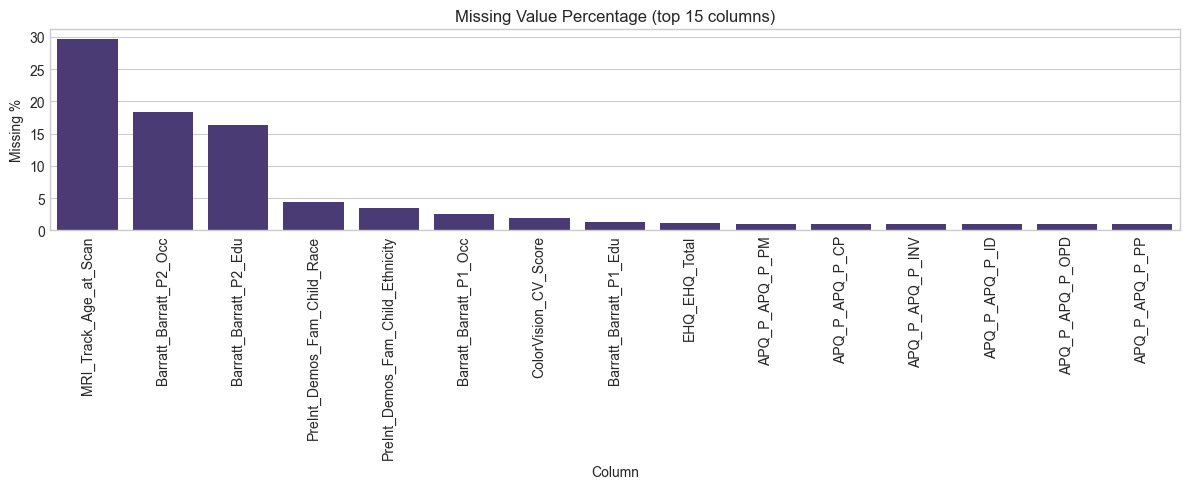

TARGET ANALYSIS: ADHD_Outcome
  ADHD_Outcome=1: 831 (68.5%)
  ADHD_Outcome=0: 382 (31.5%)

Imbalance ratio (majority:minority): 2.18:1
  ⚠ Noticeable class imbalance — SMOTE will be applied during preprocessing.
  Saved: adhd_eda_visualizations\ADHD_Outcome_distribution.png


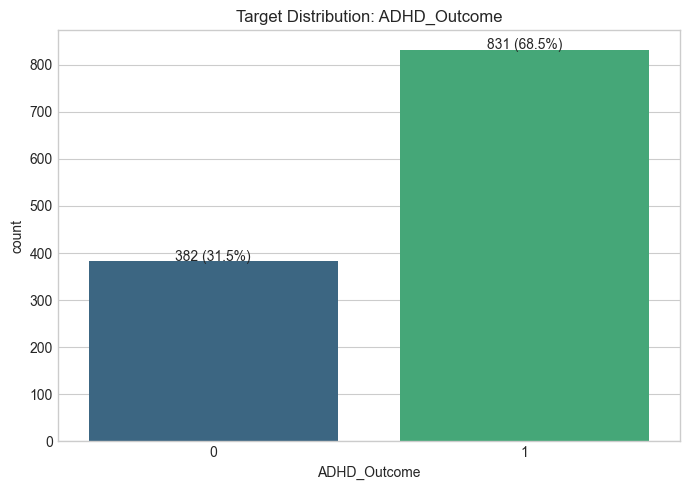

CORRELATION ANALYSIS
Top 10 features correlated with target:
SDQ_SDQ_Hyperactivity         0.558625
SDQ_SDQ_Externalizing         0.514630
SDQ_SDQ_Difficulties_Total    0.464724
SDQ_SDQ_Generating_Impact     0.410349
SDQ_SDQ_Conduct_Problems      0.275598
SDQ_SDQ_Internalizing         0.257269
SDQ_SDQ_Peer_Problems         0.219253
SDQ_SDQ_Emotional_Problems    0.205459
SDQ_SDQ_Prosocial             0.190466
Basic_Demos_Enroll_Year       0.166252
dtype: float64
  Saved: adhd_eda_visualizations\top_15_correlations.png


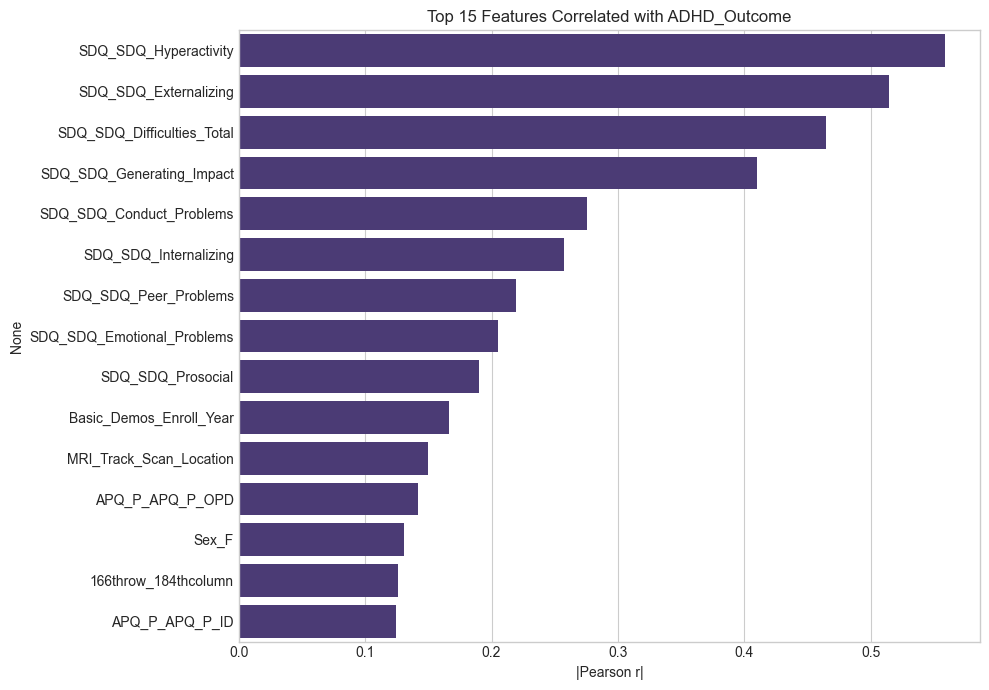

  Saved: adhd_eda_visualizations\correlation_heatmap.png


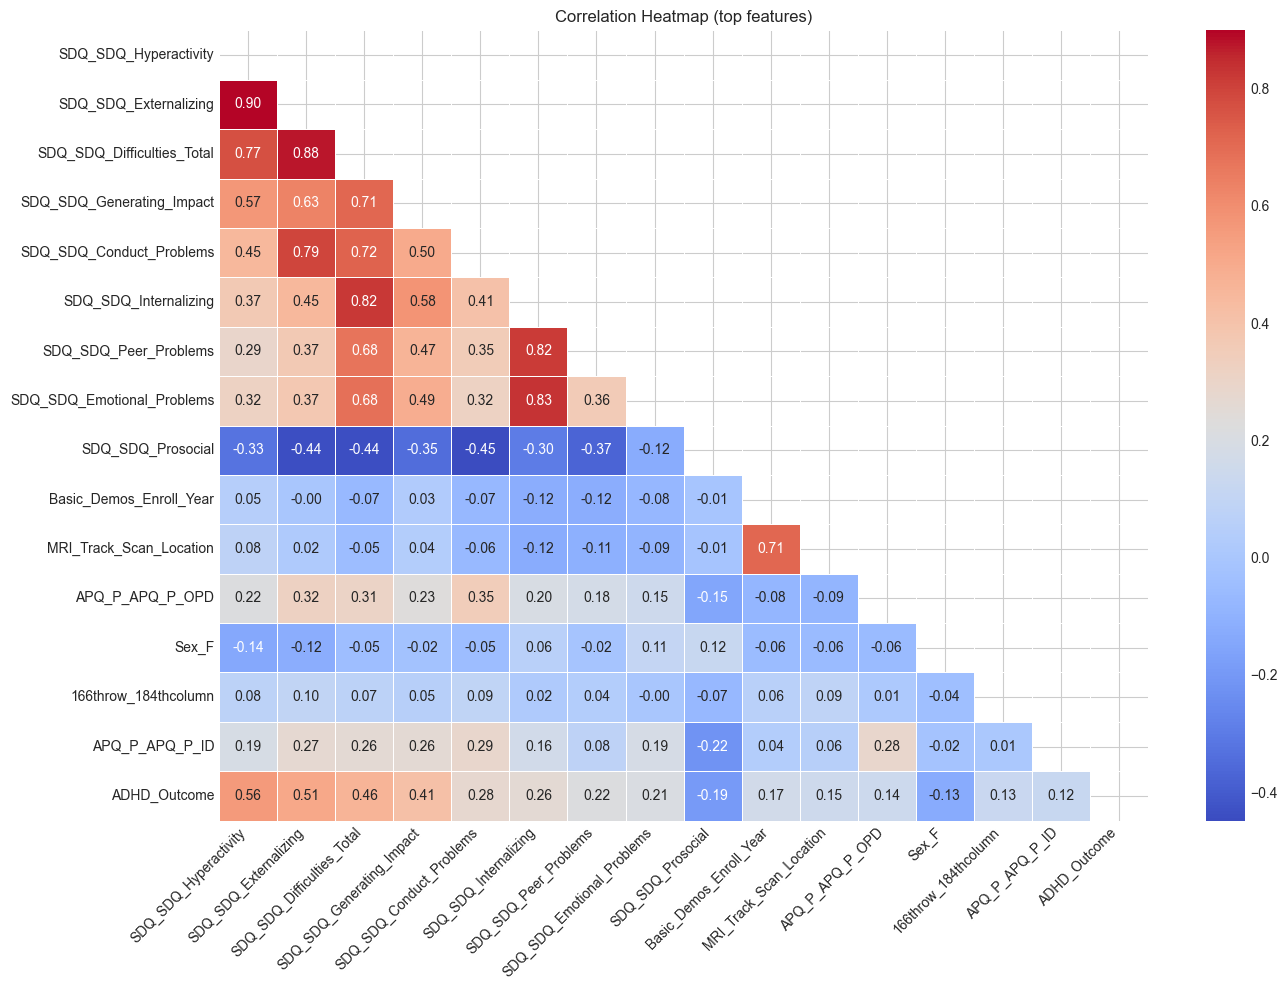

  Saved: adhd_eda_visualizations\feature_distributions.png


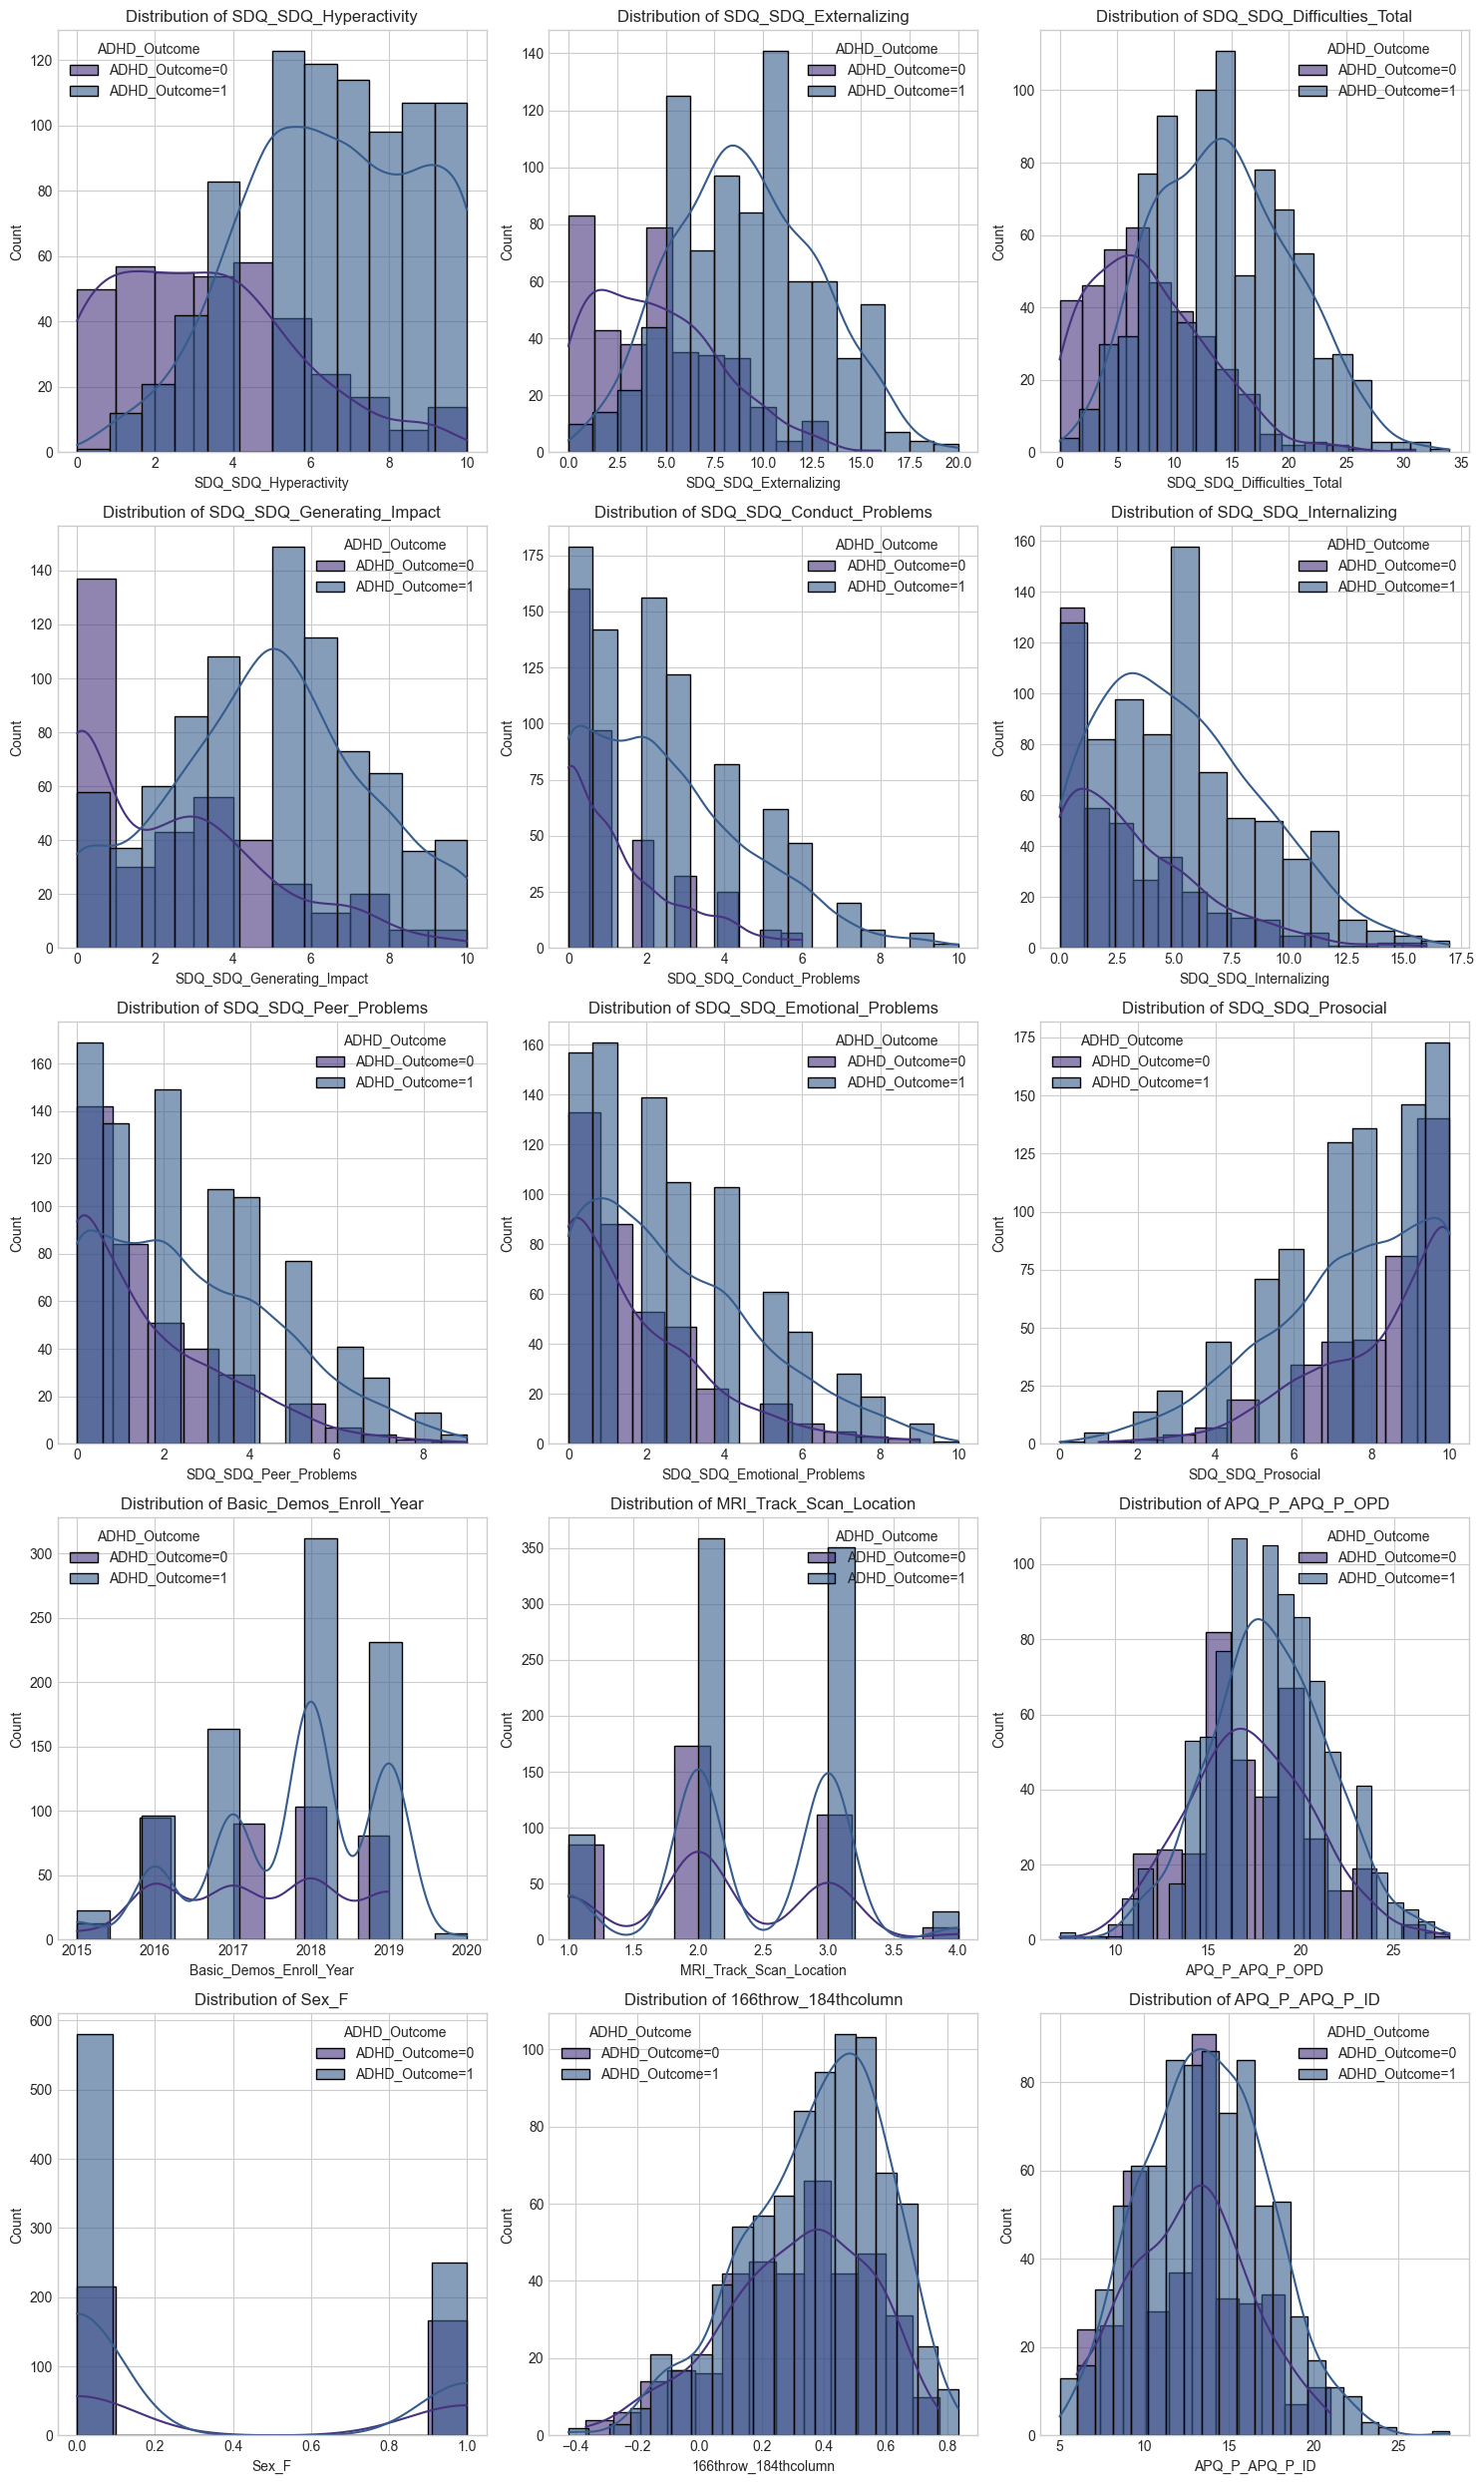

OUTLIER ANALYSIS
  Saved: adhd_eda_visualizations\outlier_boxplot.png


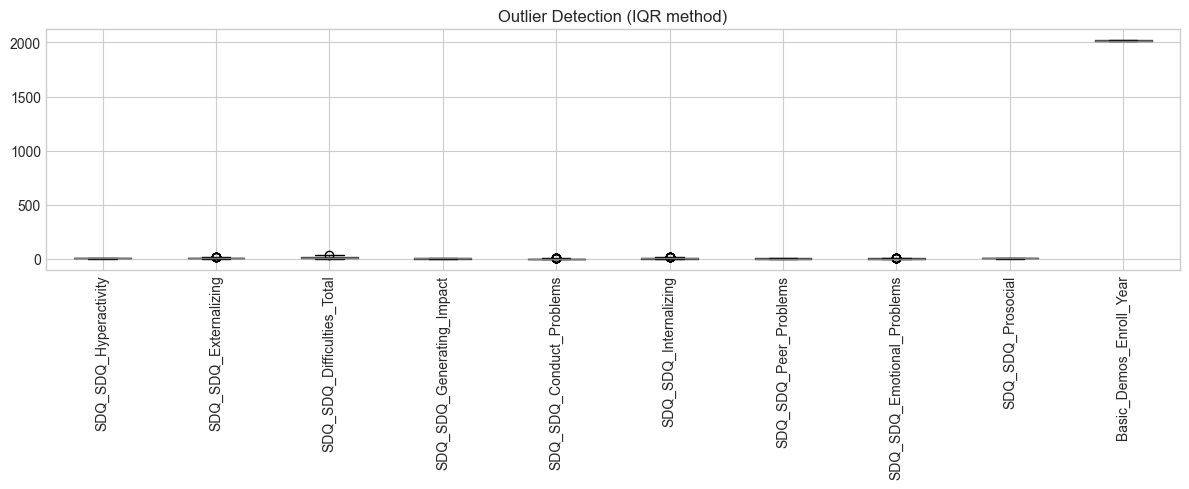

Features with highest outlier %:
  SDQ_SDQ_Conduct_Problems: 17 outliers (1.4%)
  SDQ_SDQ_Emotional_Problems: 11 outliers (0.9%)
  SDQ_SDQ_Internalizing: 10 outliers (0.8%)
  SDQ_SDQ_Externalizing: 7 outliers (0.6%)
  SDQ_SDQ_Difficulties_Total: 1 outliers (0.1%)
PCA ANALYSIS
  Saved: adhd_eda_visualizations\pca_variance.png


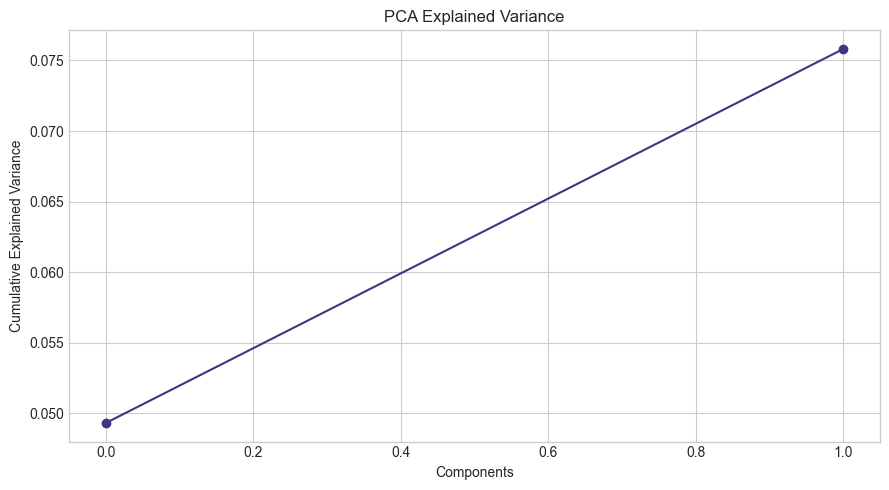

  Saved: adhd_eda_visualizations\pca_scatter.png


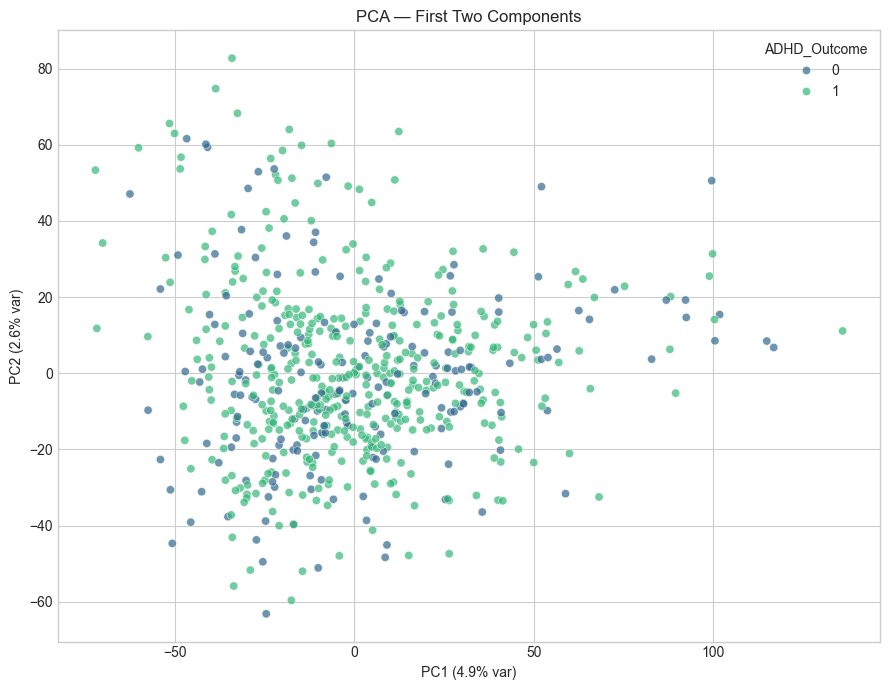

EDA complete. Visualisations saved to: adhd_eda_visualizations
  Saved: adhd_eda_visualizations\sdq_by_adhd.png


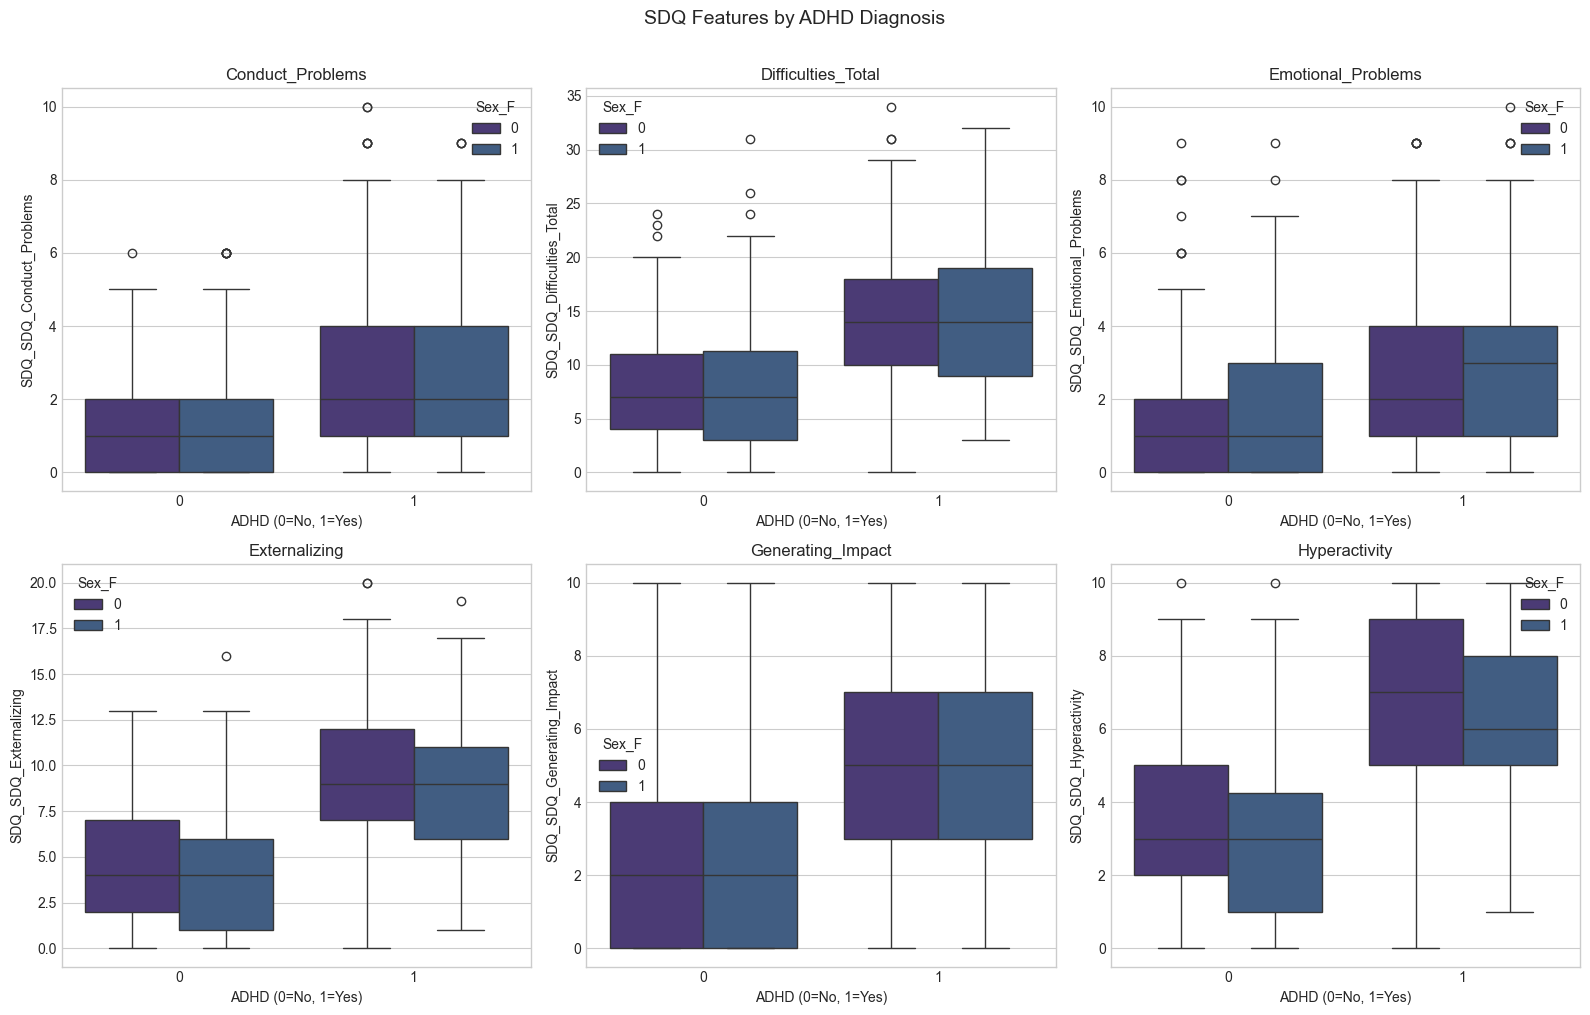


EDA process completed.


In [7]:
run_adhd_eda_colab(train, test)

In [8]:
def feature_engineering(df):

    print("Feature engineering...")
    df = df.copy()

    # 1. Impute numeric missing with median
    num_cols = df.select_dtypes(include=np.number).columns
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())

    # 2. Interaction feature
    if all(c in df.columns for c in ['Age', 'FD_mean']):
        df['Age_FD_interaction'] = df['Age'] * df['FD_mean']
        print("  + Age_FD_interaction")

    # 3. Polynomial features on FD_mean
    if 'FD_mean' in df.columns:
        df['FD_mean_sq']   = np.square(df['FD_mean'])
        df['FD_mean_cube'] = np.power(df['FD_mean'], 3)
        print("  + FD_mean polynomial features")

    # 4. Age quantile bins
    if 'Age' in df.columns:
        df['Age_bin'] = pd.qcut(df['Age'], q=5, labels=False, duplicates='drop')
        print("  + Age_bin")

    # FIX: removed FD_mean_rolling_std — rolling on unsorted rows produces noise
    # If data were sorted by participant_id + session, it could be added back.

    # 5. Cluster label (uses globally-imported KMeans — no re-import needed)
    small_num = [c for c in num_cols if c in df.columns][:5]
    cluster_data = df[small_num].fillna(df[small_num].median())
    if len(cluster_data) > 10:
        try:
            km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
            df['cluster'] = km.fit_predict(cluster_data)
            print("  + cluster label")
        except Exception as e:
            df['cluster'] = 0
            print(f"  Clustering failed ({e}), defaulting to 0")

    # 6. Session count per participant
    if 'session_id' in df.columns and 'participant_id' in df.columns:
        df['session_count'] = df.groupby('participant_id')['session_id'].transform('nunique')
        print("  + session_count")

    print(f"Feature engineering done. Shape: {df.shape}")
    return df

In [9]:
def preprocess_data(train, test, target_col='ADHD_Outcome'):
    print("\nPreprocessing...")

    drop_cols = ['participant_id', 'ADHD_Outcome', 'Sex_F', 'data_source']
    drop_cols = [c for c in drop_cols if c in train.columns]

    if target_col not in train.columns:
        raise ValueError(f"Target '{target_col}' not in training data. "
                         f"Available: {train.columns.tolist()}")

    y = train[target_col].copy()
    X = train.drop(columns=drop_cols, errors='ignore')

    test_drop = [c for c in ['participant_id', 'data_source'] if c in test.columns]
    test_X = test.drop(columns=test_drop, errors='ignore')

    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X.select_dtypes(include='object').columns.tolist()
    print(f"  Numeric: {len(num_cols)}  |  Categorical: {len(cat_cols)}")

    # ── Pipelines ────────────────────────────────────────────────
    num_pipe = Pipeline([
        ('imputer',     SimpleImputer(strategy='median')),
        ('scaler',      StandardScaler()),
        ('transformer', PowerTransformer(method='yeo-johnson'))
    ])


    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ])

    transformers = []
    if num_cols: transformers.append(('num', num_pipe, num_cols))
    if cat_cols: transformers.append(('cat', cat_pipe, cat_cols))

    preprocessor  = ColumnTransformer(transformers)
    X_proc        = preprocessor.fit_transform(X)
    test_proc     = preprocessor.transform(test_X)
    print(f"  Preprocessed shape: {X_proc.shape}")

    # FIX: use get_feature_names_out() for reliable column names
    try:
        feature_names = preprocessor.get_feature_names_out()
        feature_names = np.array([n.split('__', 1)[-1] for n in feature_names])
    except Exception:
        feature_names = np.array([f'f{i}' for i in range(X_proc.shape[1])])

    # ── Feature selection ────────────────────────────────────────
    k = min(30, X_proc.shape[1])
    selector     = SelectKBest(score_func=f_classif, k=k)
    X_sel        = selector.fit_transform(X_proc, y)
    test_sel     = selector.transform(test_proc)
    sel_features = feature_names[selector.get_support()]
    print(f"  Selected top {len(sel_features)} features.")

    return X_sel, test_sel, y, sel_features, preprocessor

In [11]:
def apply_pca(X, test_X, min_variance=0.95):
    """PCA dimensionality reduction. FIX: plt.show() added."""
    print("\nApplying PCA...")
    pca       = PCA(n_components=min_variance)
    X_pca     = pca.fit_transform(X)
    test_pca  = pca.transform(test_X)
    print(f"  {X.shape[1]} → {X_pca.shape[1]} components  |  variance retained: {pca.explained_variance_ratio_.sum():.2%}")

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(np.cumsum(pca.explained_variance_ratio_), 'o--')
    ax.axhline(min_variance, color='red', linestyle=':', label=f'{min_variance:.0%} threshold')
    ax.set_xlabel('Components')
    ax.set_ylabel('Cumulative Explained Variance')
    ax.set_title('PCA Explained Variance')
    ax.legend()
    plt.tight_layout()
    plt.savefig('plots/pca_variance.png', dpi=150, bbox_inches='tight')
    plt.show()          # FIX: show in notebook
    plt.close(fig)

    return X_pca, test_pca, pca

In [12]:
def split_data(X, y, test_size=0.2):
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=RANDOM_STATE, stratify=y)
    print(f"\nTrain: {X_tr.shape[0]:,}  |  Test: {X_te.shape[0]:,}")
    return X_tr, X_te, y_tr, y_te


def apply_smote(X_train, y_train):
    """Apply SMOTE to the TRAINING set only to address class imbalance."""
    if not SMOTE_AVAILABLE:
        print("  SMOTE skipped (imbalanced-learn not installed).")
        return X_train, y_train
    before = pd.Series(y_train).value_counts().to_dict()
    sm = SMOTE(random_state=RANDOM_STATE)
    X_res, y_res = sm.fit_resample(X_train, y_train)
    after = pd.Series(y_res).value_counts().to_dict()
    print(f"  SMOTE: {before} → {after}")
    return X_res, y_res

In [13]:
def evaluate_models(X, y, cv=None):

    if cv is None:
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

    print("\nCross-validating models...")

    # FIX: GradientBoostingClassifier now included
    models = {
        'Logistic Regression':   LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'),
        'Random Forest':         RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
        'Gradient Boosting':     GradientBoostingClassifier(random_state=RANDOM_STATE),   # assignment requirement
        'XGBoost':               XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', scale_pos_weight=1),
        'LightGBM':              LGBMClassifier(random_state=RANDOM_STATE, class_weight='balanced', verbose=-1),
        'SVM':                   SVC(probability=True, random_state=RANDOM_STATE, class_weight='balanced'),
        'MLP':                   MLPClassifier(random_state=RANDOM_STATE, max_iter=500),
        'AdaBoost':              AdaBoostClassifier(random_state=RANDOM_STATE),
    }

    metrics  = ['accuracy', 'precision_weighted', 'recall_weighted', 'f1_weighted', 'roc_auc']
    results  = {}

    for name, model in models.items():
        print(f"\n  {name}")
        pipe   = Pipeline([('scaler', StandardScaler()), ('model', model)])
        scores = {}
        for metric in metrics:
            try:
                cv_s = cross_val_score(pipe, X, y, cv=cv, scoring=metric)
                scores[metric] = {'mean': cv_s.mean(), 'std': cv_s.std()}
                print(f"    {metric:25s}: {cv_s.mean():.4f} ± {cv_s.std():.4f}")
            except Exception as e:
                print(f"    {metric}: ERROR ({e})")
                scores[metric] = {'mean': 0, 'std': 0}
        results[name] = scores

    ranked = sorted(results.items(), key=lambda x: x[1]['roc_auc']['mean'], reverse=True)
    print("\nRanking by ROC-AUC:")
    for i, (n, s) in enumerate(ranked, 1):
        print(f"  {i}. {n}: {s['roc_auc']['mean']:.4f}")

    return results

In [14]:
def tune_hyperparameters(X, y, models_to_tune, n_iter=20):

    print("\nTuning hyperparameters with RandomizedSearchCV...")

    
    param_dists = {
        'Logistic Regression': {
            'model__C':       [0.01, 0.1, 1, 10, 100],
            'model__penalty': ['l1', 'l2', 'elasticnet'],
            'model__solver':  ['saga'],
            'model__l1_ratio': [0.3, 0.5, 0.7]   
        },
        'Random Forest': {
            'model__n_estimators':    [100, 200, 300],
            'model__max_depth':       [3, 5, 7, 10, None],
            'model__min_samples_split': [2, 5, 10],
            'model__min_samples_leaf':  [1, 2, 4]
        },
        'Gradient Boosting': {
            'model__n_estimators':  [100, 200],
            'model__max_depth':     [3, 5, 7],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__subsample':     [0.8, 1.0]
        },
        'XGBoost': {
            'model__n_estimators':    [100, 200, 300],
            'model__max_depth':       [3, 5, 7],
            'model__learning_rate':   [0.01, 0.05, 0.1],
            'model__subsample':       [0.8, 0.9, 1.0],
            'model__colsample_bytree': [0.8, 0.9, 1.0]
        },
        'LightGBM': {
            'model__n_estimators':  [100, 200, 300],
            'model__max_depth':     [3, 5, 7, -1],
            'model__learning_rate': [0.01, 0.05, 0.1],
            'model__num_leaves':    [31, 50, 70]
        },
        'SVM': {
            'model__C':      [0.1, 1, 10, 100],
            'model__gamma':  ['scale', 'auto', 0.1, 0.01],
            'model__kernel': ['rbf', 'linear']
        },
        'MLP': {
            'model__hidden_layer_sizes': [(50,), (100,), (50, 50), (100, 50)],
            'model__activation':         ['relu', 'tanh'],
            'model__alpha':              [0.0001, 0.001, 0.01],
            'model__learning_rate':      ['constant', 'adaptive']
        },
        'AdaBoost': {
            'model__n_estimators':  [50, 100, 200],
            'model__learning_rate': [0.01, 0.1, 0.5, 1.0]
        }
    }

    base_models = {
        'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, class_weight='balanced'),
        'Random Forest':        RandomForestClassifier(random_state=RANDOM_STATE, class_weight='balanced'),
        'Gradient Boosting':    GradientBoostingClassifier(random_state=RANDOM_STATE),
        'XGBoost':              XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss'),
        'LightGBM':             LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
        'SVM':                  SVC(probability=True, random_state=RANDOM_STATE, class_weight='balanced'),
        'MLP':                  MLPClassifier(random_state=RANDOM_STATE, max_iter=500),
        'AdaBoost':             AdaBoostClassifier(random_state=RANDOM_STATE)
    }

    tuned = {}
    for name in models_to_tune:
        if name not in base_models:
            print(f"  '{name}' not found — skipping.")
            continue
        print(f"\n  Tuning {name}...")
        pipe = Pipeline([('scaler', StandardScaler()), ('model', base_models[name])])
        rs   = RandomizedSearchCV(
            estimator=pipe,
            param_distributions=param_dists.get(name, {}),
            n_iter=n_iter,
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
            scoring='roc_auc',
            n_jobs=-1,
            random_state=RANDOM_STATE,
            verbose=0
        )
        try:
            rs.fit(X, y)
            print(f"    Best params : {rs.best_params_}")
            print(f"    Best ROC-AUC: {rs.best_score_:.4f}")
            tuned[name] = rs.best_estimator_
        except Exception as e:
            print(f"    Tuning failed: {e}")

    return tuned

In [15]:
# ─── Plotting helpers ────────────────────────────────────────────

def plot_model_comparison(results, metric='roc_auc'):
    """Bar chart of cross-val scores. FIX: plt.show() + plt.close() added."""
    names  = list(results.keys())
    means  = [results[m][metric]['mean'] for m in names]
    errs   = [results[m][metric]['std']  for m in names]
    order  = np.argsort(means)
    s_names = [names[i] for i in order]
    s_means = [means[i] for i in order]
    s_errs  = [errs[i]  for i in order]

    fig, ax = plt.subplots(figsize=(10, 6))
    bars = ax.barh(range(len(s_names)), s_means, xerr=s_errs, align='center', alpha=0.7, capsize=4)
    bars[0].set_color('#F0997B')
    bars[-1].set_color('#5DCAA5')
    for i, bar in enumerate(bars):
        ax.text(bar.get_width() + s_errs[i] + 0.005, bar.get_y() + bar.get_height()/2,
                f'{s_means[i]:.4f}', va='center', fontsize=9)
    ax.set_yticks(range(len(s_names)))
    ax.set_yticklabels(s_names)
    ax.set_xlabel(metric.upper())
    ax.set_title(f'Model Comparison — {metric.upper()}')
    ax.grid(axis='x', linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(f'plots/comparison_{metric}.png', dpi=150, bbox_inches='tight')
    plt.show()          # FIX
    plt.close(fig)


def plot_roc_curves(models, X, y):
    """ROC curves for all models. FIX: plt.show() + plt.close() added."""
    fig, ax = plt.subplots(figsize=(10, 7))
    for name, model in models.items():
        try:
            y_sc = model.predict_proba(X)[:, 1]
            fpr, tpr, _ = roc_curve(y, y_sc)
            ax.plot(fpr, tpr, lw=2, label=f'{name} (AUC={auc(fpr,tpr):.4f})')
        except Exception as e:
            print(f"  ROC error {name}: {e}")
    ax.plot([0,1],[0,1],'k--', lw=1)
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title('ROC Curves')
    ax.legend(loc='lower right', fontsize=9)
    plt.tight_layout()
    plt.savefig('plots/roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()          # FIX
    plt.close(fig)


def plot_precision_recall_curves(models, X, y):
    """Precision-Recall curves. FIX: plt.show() + plt.close() added."""
    fig, ax = plt.subplots(figsize=(10, 7))
    for name, model in models.items():
        try:
            y_sc = model.predict_proba(X)[:, 1]
            prec, rec, _ = precision_recall_curve(y, y_sc)
            ax.plot(rec, prec, lw=2, label=f'{name} (AUC={auc(rec,prec):.4f})')
        except Exception as e:
            print(f"  PR error {name}: {e}")
    ax.set_xlabel('Recall')
    ax.set_ylabel('Precision')
    ax.set_title('Precision-Recall Curves')
    ax.legend(loc='lower left', fontsize=9)
    plt.tight_layout()
    plt.savefig('plots/pr_curves.png', dpi=150, bbox_inches='tight')
    plt.show()          # FIX
    plt.close(fig)


def plot_confusion_matrices(models, X, y, normalize=False):
    """Grid of confusion matrices. FIX: plt.show() + plt.close() added."""
    n = len(models)
    ncols = min(3, n)
    nrows = (n + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows))
    axes = np.array(axes).flatten()

    for i, (name, model) in enumerate(models.items()):
        ax = axes[i]
        try:
            y_pred = model.predict(X)
            cm = confusion_matrix(y, y_pred)
            if normalize:
                cm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
                fmt = '.2f'
            else:
                fmt = 'd'
            sns.heatmap(cm, annot=True, fmt=fmt, cmap='Blues', ax=ax)
            ax.set_xlabel('Predicted')
            ax.set_ylabel('Actual')
            ax.set_title(f'{name}')
        except Exception as e:
            ax.text(0.5, 0.5, str(e), ha='center', va='center', fontsize=8)
            ax.set_title(f'{name} — ERROR')

    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle('Confusion Matrices', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig('plots/confusion_matrices.png', dpi=150, bbox_inches='tight')
    plt.show()          # FIX
    plt.close(fig)

In [16]:
def build_ensemble_model(models, X_train, y_train, X_val, y_val):

    print("\nBuilding stacking ensemble...")
    estimators = list(models.items())
    stack = StackingClassifier(
        estimators=estimators,
        final_estimator=LogisticRegression(random_state=RANDOM_STATE),
        stack_method='auto',
        n_jobs=-1,
        passthrough=False
    )
    stack.fit(X_train, y_train)

    # FIX: evaluate on VALIDATION set, not training set
    y_pred  = stack.predict(X_val)
    y_score = stack.predict_proba(X_val)[:, 1]
    print("Ensemble performance on VALIDATION set:")
    print(f"  Accuracy  : {accuracy_score(y_val, y_pred):.4f}")
    print(f"  Precision : {precision_score(y_val, y_pred, average='weighted'):.4f}")
    print(f"  Recall    : {recall_score(y_val, y_pred, average='weighted'):.4f}")
    print(f"  F1        : {f1_score(y_val, y_pred, average='weighted'):.4f}")
    print(f"  ROC-AUC   : {roc_auc_score(y_val, y_score):.4f}")
    return stack

In [17]:
def interpret_model(model, X, feature_names):
    """
    SHAP + feature importance + partial dependence.
    FIX: PartialDependenceDisplay now uses model_to_explain + preprocessed X,
         avoiding double-application of the pipeline's scaler.
    """
    print("\nInterpreting model...")

    # Extract inner estimator and preprocessed data from pipeline
    if hasattr(model, 'named_steps'):
        model_to_explain = model.named_steps['model']
        X_proc = model.named_steps['scaler'].transform(X)
    else:
        model_to_explain = model
        X_proc = X

    model_type = type(model_to_explain).__name__
    feat_list  = list(feature_names)

    # ── SHAP ────────────────────────────────────────────────────
    shap_values = None
    try:
        if any(k in model_type for k in ('XGB', 'Random', 'LGBM', 'Gradient')):
            print("  Using TreeExplainer...")
            explainer   = shap.TreeExplainer(model_to_explain)
            n           = min(500, X_proc.shape[0])
            shap_values = explainer.shap_values(X_proc[:n])
            if isinstance(shap_values, list) and len(shap_values) == 2:
                shap_values = shap_values[1]
        else:
            print("  Using KernelExplainer (slow — using 50 background samples)...")
            bg          = shap.kmeans(X_proc, min(50, X_proc.shape[0]))
            explainer   = shap.KernelExplainer(model_to_explain.predict_proba, bg)
            n           = min(50, X_proc.shape[0])
            shap_values = explainer.shap_values(X_proc[:n])
            if isinstance(shap_values, list):
                shap_values = shap_values[1]

        fig, ax = plt.subplots(figsize=(10, 7))
        shap.summary_plot(shap_values, X_proc[:n], feature_names=feat_list,
                          plot_type='bar', show=False)
        plt.title('SHAP Feature Importance')
        plt.tight_layout()
        plt.savefig('plots/shap_importance.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()

        fig, ax = plt.subplots(figsize=(10, 7))
        shap.summary_plot(shap_values, X_proc[:n], feature_names=feat_list, show=False)
        plt.title('SHAP Feature Impact (Beeswarm)')
        plt.tight_layout()
        plt.savefig('plots/shap_impact.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()

    except Exception as e:
        print(f"  SHAP failed: {e}. Falling back to feature_importances_.")
        if hasattr(model_to_explain, 'feature_importances_'):
            imp   = model_to_explain.feature_importances_
            order = np.argsort(imp)[::-1]
            fig, ax = plt.subplots(figsize=(10, 6))
            ax.bar(range(len(order)), imp[order])
            ax.set_xticks(range(len(order)))
            ax.set_xticklabels([feat_list[i] if i < len(feat_list) else f'f{i}'
                                 for i in order], rotation=90, fontsize=8)
            ax.set_title('Feature Importance')
            plt.tight_layout()
            plt.savefig('plots/feature_importance.png', dpi=150, bbox_inches='tight')
            plt.show()
            plt.close()

    # ── Partial Dependence Plots ─────────────────────────────────
    # FIX: use model_to_explain + X_proc to avoid double-preprocessing
    try:
        if shap_values is not None:
            top_idx = np.argsort(-np.abs(shap_values).mean(0))[:2].tolist()
        elif hasattr(model_to_explain, 'feature_importances_'):
            top_idx = np.argsort(-model_to_explain.feature_importances_)[:2].tolist()
        else:
            top_idx = [0, 1]

        top_idx = [i for i in top_idx if i < X_proc.shape[1]][:2]

        fig, ax = plt.subplots(1, len(top_idx), figsize=(6*len(top_idx), 5))
        # FIX: pass model_to_explain (not full pipeline) with already-preprocessed X_proc
        PartialDependenceDisplay.from_estimator(
            model_to_explain, X_proc, top_idx,
            kind='both', subsample=200, n_jobs=-1,
            grid_resolution=20, random_state=RANDOM_STATE,
            feature_names=feat_list,
            ax=ax if len(top_idx) > 1 else [ax]
        )
        plt.suptitle('Partial Dependence Plots — Top Features')
        plt.tight_layout()
        plt.savefig('plots/partial_dependence.png', dpi=150, bbox_inches='tight')
        plt.show()
        plt.close()
        print(f"  PDP generated for features: {[feat_list[i] if i < len(feat_list) else f'f{i}' for i in top_idx]}")

    except Exception as e:
        print(f"  PDP failed: {e}")

In [18]:
def generate_submission(model, test_X, test_df, out='ADHD_submission.csv'):
    preds = model.predict(test_X)
    sub   = pd.DataFrame({'participant_id': test_df['participant_id'], 'ADHD_Outcome': preds})
    sub.to_csv(out, index=False)
    pos = preds.sum()
    print(f"Submission saved: {out}  |  ADHD={pos} ({pos/len(preds):.1%})  No-ADHD={len(preds)-pos}")
    return sub


def print_summary(results, best_name, tuned, runtime):
    print("\n" + "="*70)
    print("ADHD CLASSIFICATION PIPELINE — SUMMARY")
    print("="*70)

    print("\n── Model Ranking (ROC-AUC) ──────────────────────────")
    ranked = sorted([(n, r['roc_auc']['mean']) for n,r in results.items()],
                    key=lambda x: x[1], reverse=True)
    for i, (n, s) in enumerate(ranked, 1):
        tag = ' ← best' if i==1 else ' ← worst' if i==len(ranked) else ''
        print(f"  {i}. {n}: {s:.4f}{tag}")

    print(f"\n── Tuned models: {', '.join(tuned.keys())}")
    print(f"── Best individual: {best_name}")

    h, r = divmod(runtime, 3600)
    m, s = divmod(r, 60)
    print(f"── Total runtime: {int(h)}h {int(m)}m {int(s)}s")

    print("\n── Recommendations ──────────────────────────────────")
    print("  1. Use the best model's top SHAP features as clinical screening targets.")
    print("  2. fMRI connectivity features with high importance may guide neuroimaging protocols.")
    print("  3. Socio-demographic features (Age, Sex) should be stratified in clinical use.")
    print("  4. Retrain periodically as new labelled data becomes available.")
    print("  5. Consider fairness audits across demographic subgroups before deployment.")
    print("="*70)

Feature engineering...
  + cluster label
Feature engineering done. Shape: (1213, 19932)
Feature engineering...
  + cluster label
Feature engineering done. Shape: (304, 19930)

Preprocessing...
  Numeric: 19928  |  Categorical: 0
  Preprocessed shape: (1213, 19928)
  Selected top 30 features.

Applying PCA...
  30 → 23 components  |  variance retained: 95.97%


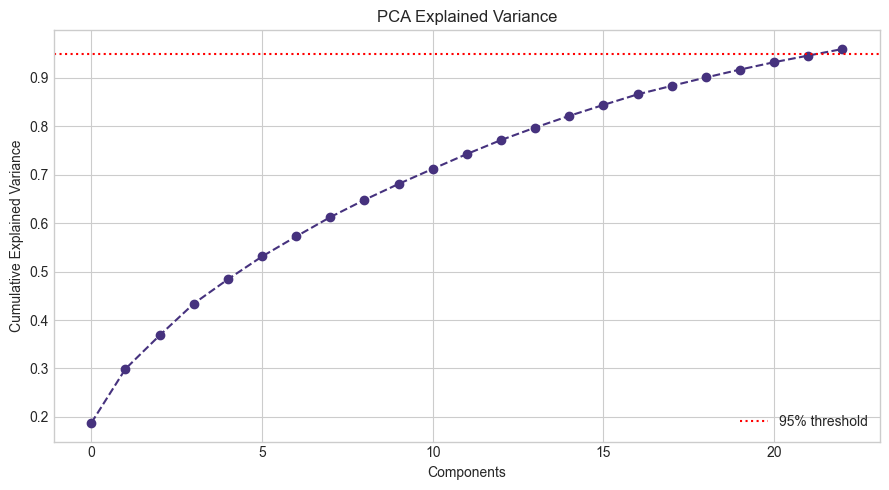


Train: 970  |  Test: 243
  SMOTE: {1: 665, 0: 305} → {1: 665, 0: 665}

Cross-validating models...

  Logistic Regression
    accuracy                 : 0.8143 ± 0.0091
    precision_weighted       : 0.8154 ± 0.0092
    recall_weighted          : 0.8143 ± 0.0091
    f1_weighted              : 0.8141 ± 0.0091
    roc_auc                  : 0.8876 ± 0.0044

  Random Forest
    accuracy                 : 0.8617 ± 0.0137
    precision_weighted       : 0.8632 ± 0.0131
    recall_weighted          : 0.8617 ± 0.0137
    f1_weighted              : 0.8615 ± 0.0138
    roc_auc                  : 0.9339 ± 0.0088

  Gradient Boosting
    accuracy                 : 0.8241 ± 0.0129
    precision_weighted       : 0.8251 ± 0.0135
    recall_weighted          : 0.8241 ± 0.0129
    f1_weighted              : 0.8239 ± 0.0128
    roc_auc                  : 0.8990 ± 0.0117

  XGBoost
    accuracy                 : 0.8556 ± 0.0120
    precision_weighted       : 0.8574 ± 0.0125
    recall_weighted          :

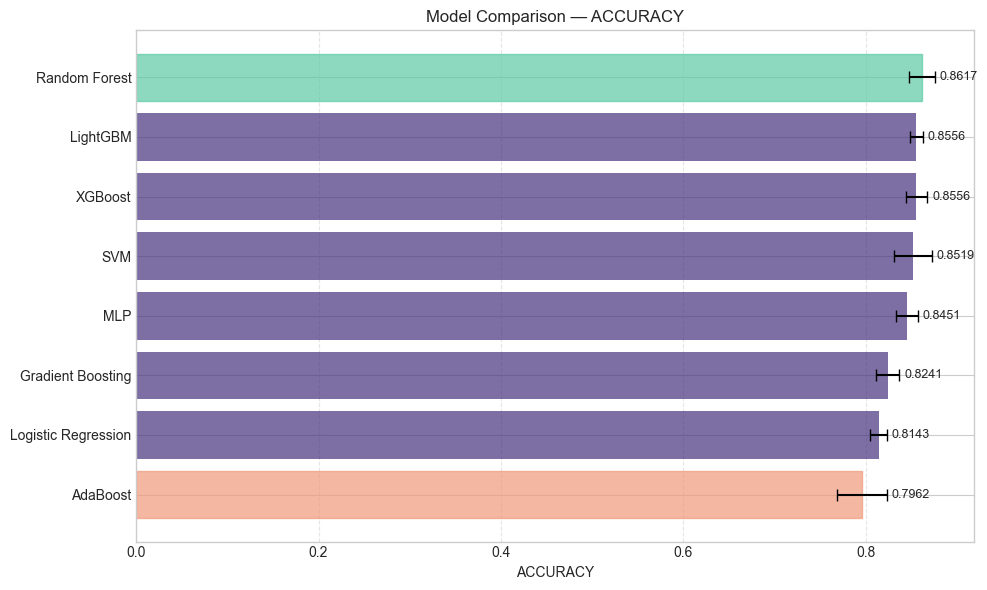

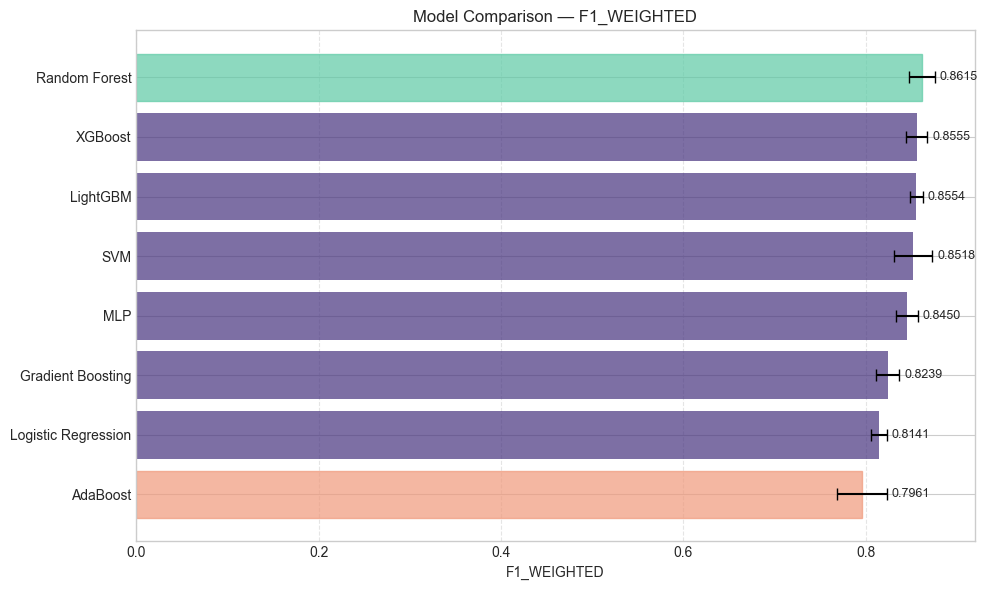

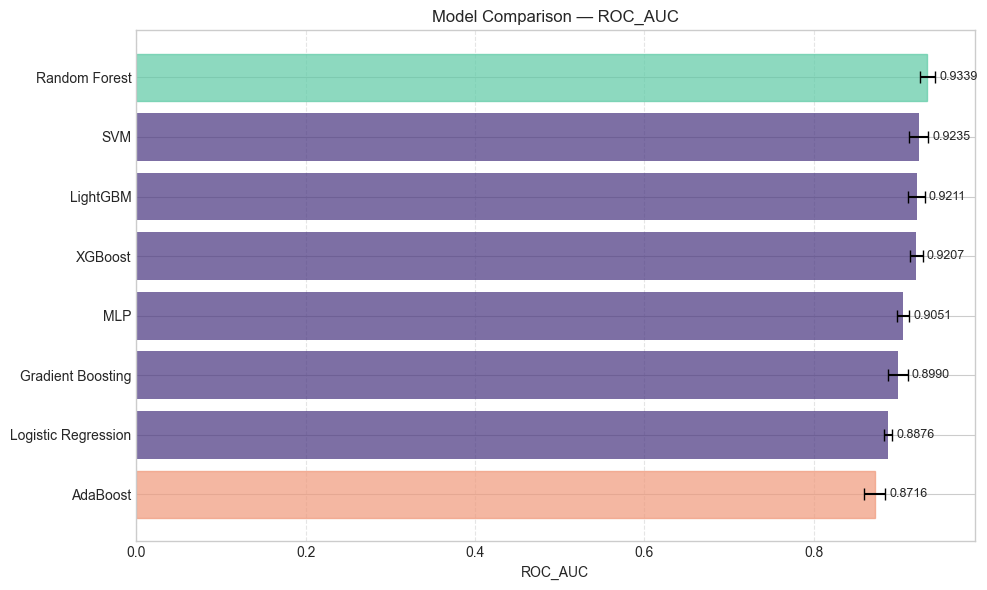


Top 3 models selected for tuning: ['Random Forest', 'SVM', 'LightGBM']

Tuning hyperparameters with RandomizedSearchCV...

  Tuning Random Forest...
    Best params : {'model__n_estimators': 300, 'model__min_samples_split': 2, 'model__min_samples_leaf': 1, 'model__max_depth': None}
    Best ROC-AUC: 0.9318

  Tuning SVM...
    Best params : {'model__kernel': 'rbf', 'model__gamma': 0.1, 'model__C': 1}
    Best ROC-AUC: 0.9407

  Tuning LightGBM...
    Best params : {'model__num_leaves': 50, 'model__n_estimators': 300, 'model__max_depth': -1, 'model__learning_rate': 0.1}
    Best ROC-AUC: 0.9267

Evaluating tuned models on held-out test set...

  Random Forest:
    accuracy    : 0.7654
    precision   : 0.7680
    recall      : 0.7654
    f1          : 0.7666
    roc_auc     : 0.8312

  SVM:
    accuracy    : 0.7860
    precision   : 0.7797
    recall      : 0.7860
    f1          : 0.7735
    roc_auc     : 0.8400

  LightGBM:
    accuracy    : 0.7531
    precision   : 0.7549
    recall

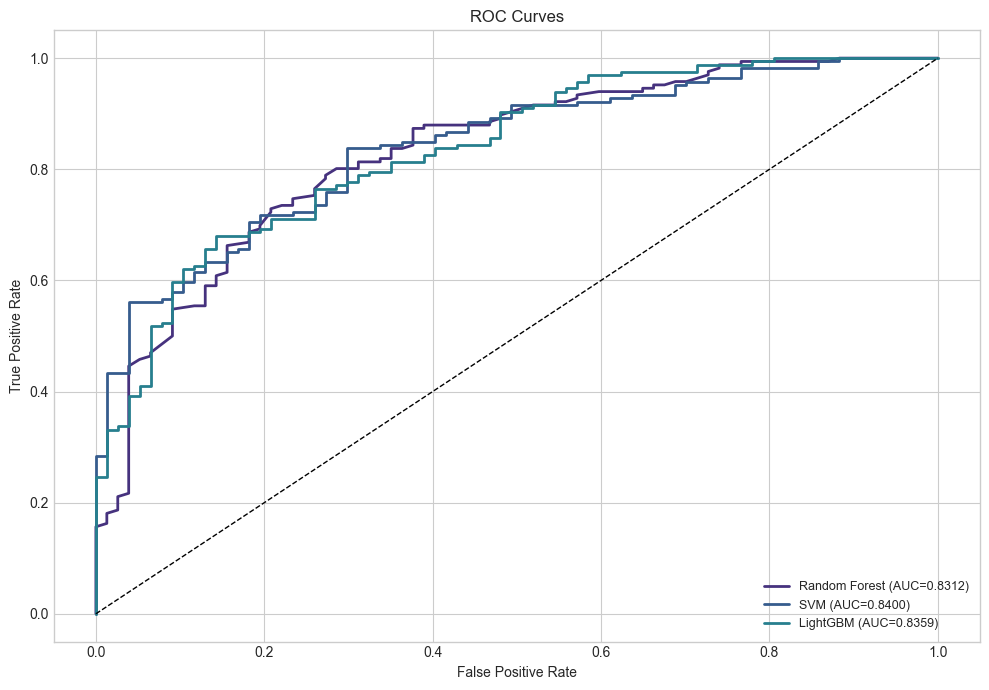

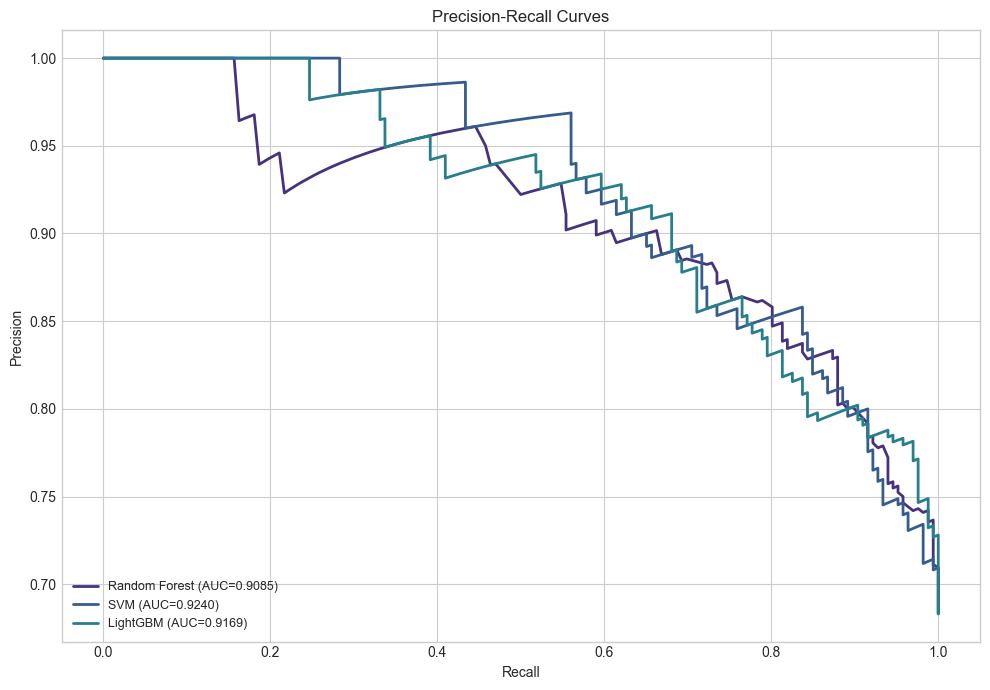

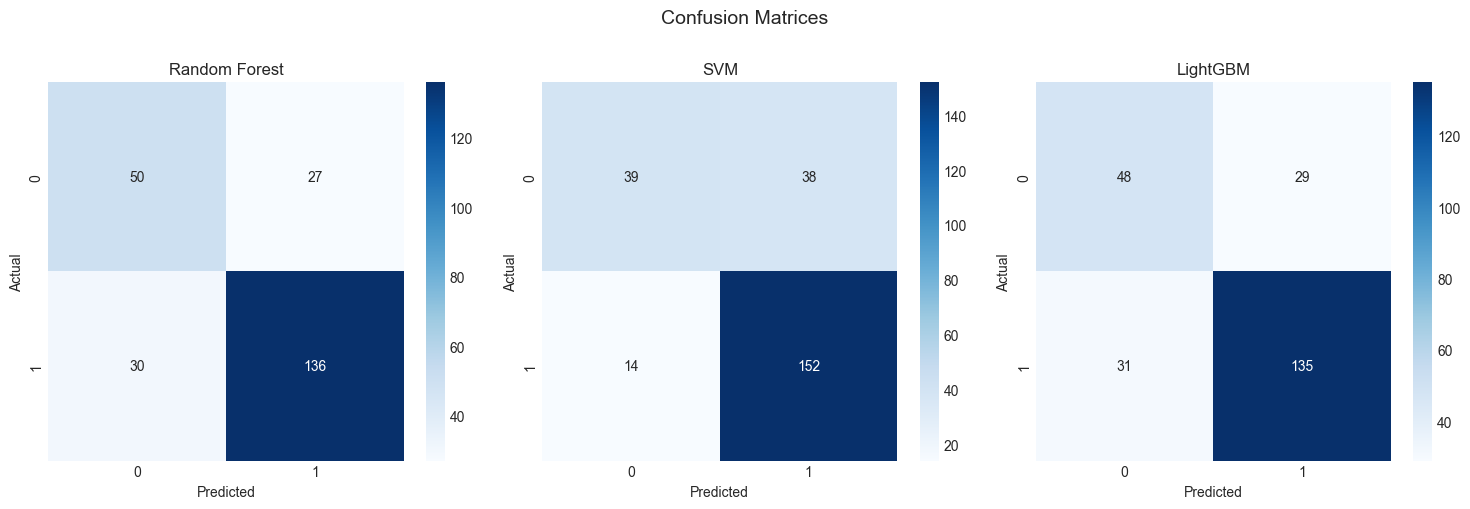


Building stacking ensemble...
Ensemble performance on VALIDATION set:
  Accuracy  : 0.7901
  Precision : 0.7833
  Recall    : 0.7901
  F1        : 0.7822
  ROC-AUC   : 0.8460

Final model: Ensemble  (ROC-AUC: 0.8460)

Interpreting model...
  Using KernelExplainer (slow — using 50 background samples)...


  0%|          | 0/50 [00:00<?, ?it/s]

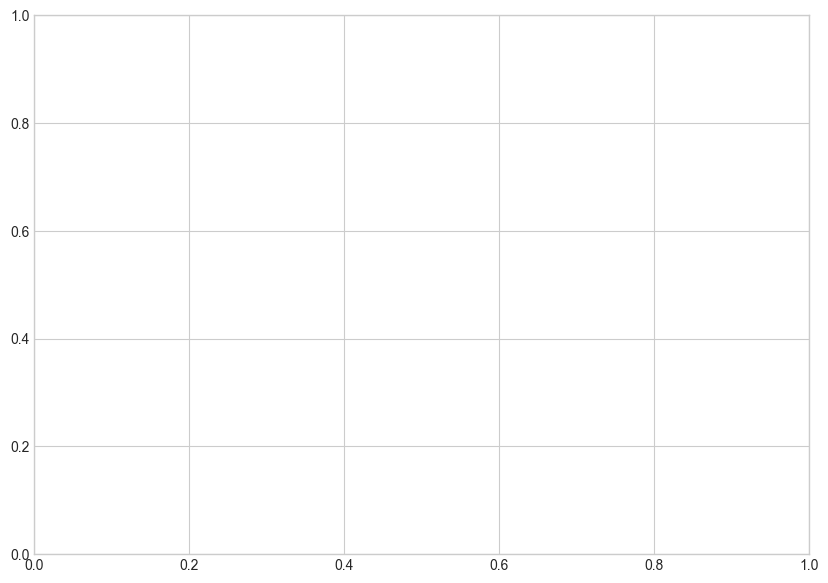

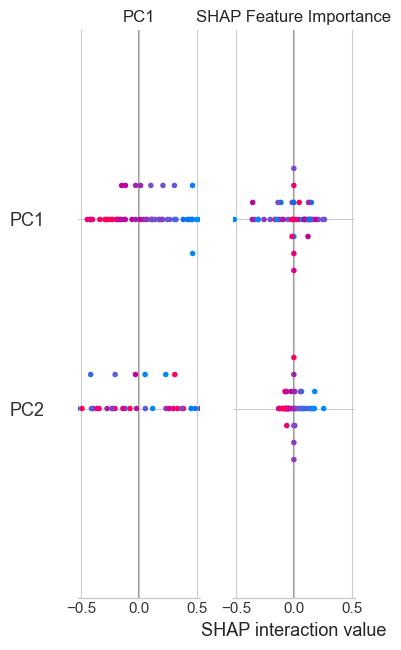

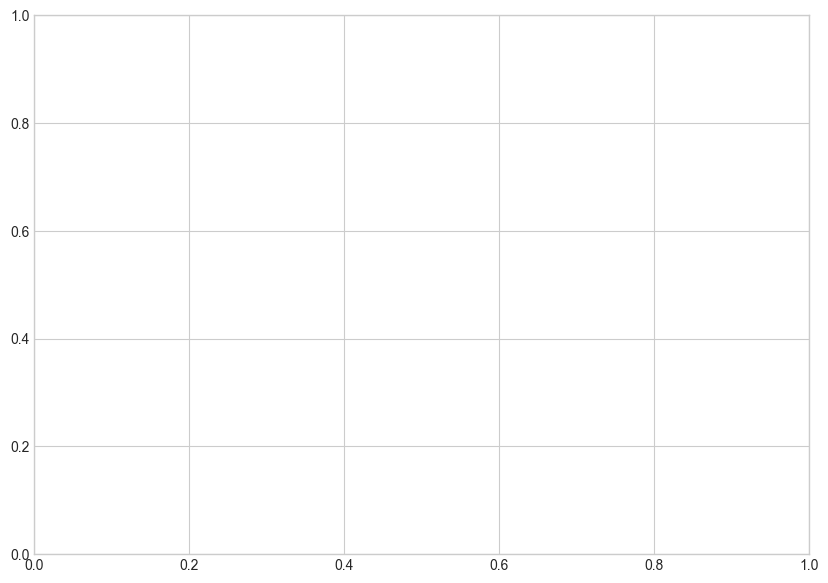

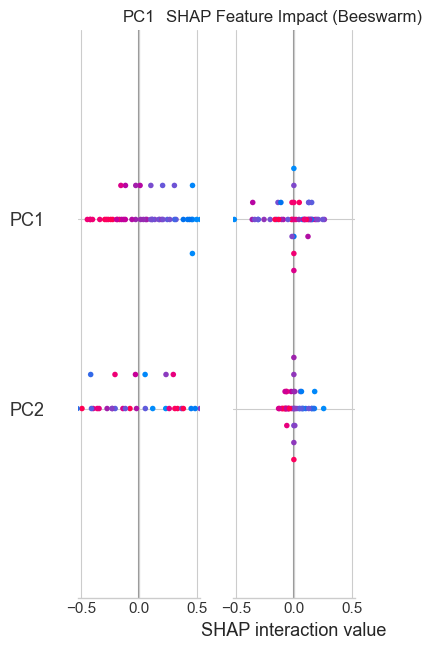

  PDP failed: '<' not supported between instances of 'list' and 'int'

Retraining final model on full data...
Submission saved: ADHD_submission.csv  |  ADHD=267 (87.8%)  No-ADHD=37

ADHD CLASSIFICATION PIPELINE — SUMMARY

── Model Ranking (ROC-AUC) ──────────────────────────
  1. Random Forest: 0.9339 ← best
  2. SVM: 0.9235
  3. LightGBM: 0.9211
  4. XGBoost: 0.9207
  5. MLP: 0.9051
  6. Gradient Boosting: 0.8990
  7. Logistic Regression: 0.8876
  8. AdaBoost: 0.8716 ← worst

── Tuned models: Random Forest, SVM, LightGBM
── Best individual: SVM
── Total runtime: 0h 39m 50s

── Recommendations ──────────────────────────────────
  1. Use the best model's top SHAP features as clinical screening targets.
  2. fMRI connectivity features with high importance may guide neuroimaging protocols.
  3. Socio-demographic features (Age, Sex) should be stratified in clinical use.
  4. Retrain periodically as new labelled data becomes available.
  5. Consider fairness audits across demographic subgro

In [19]:
# ═══════════════════════════════════════════════════════════════
# MAIN PIPELINE EXECUTION
# ═══════════════════════════════════════════════════════════════
start = time.time()

# 1. Feature engineering
train_fe = feature_engineering(train)
test_fe  = feature_engineering(test)

# 2. Preprocessing (OrdinalEncoder + get_feature_names_out)
X, test_X, y, feat_names, preprocessor = preprocess_data(train_fe, test_fe, 'ADHD_Outcome')

# 3. PCA
X_pca, test_pca, pca_model = apply_pca(X, test_X, min_variance=0.95)
pca_feat_names = [f'PC{i+1}' for i in range(X_pca.shape[1])]

# 4. Train/Val split
X_tr, X_te, y_tr, y_te = split_data(X_pca, y, test_size=0.2)

# 5. SMOTE on training set ONLY (FIX: not applied to val/test)
X_tr_bal, y_tr_bal = apply_smote(X_tr, y_tr)

# 6. Cross-validate all models
cv_results = evaluate_models(X_tr_bal, y_tr_bal)

for metric in ['accuracy', 'f1_weighted', 'roc_auc']:
    plot_model_comparison(cv_results, metric)

# 7. Select top 3 by ROC-AUC for tuning
top3 = [n for n, _ in sorted(cv_results.items(),
         key=lambda x: x[1]['roc_auc']['mean'], reverse=True)[:3]]
print(f"\nTop 3 models selected for tuning: {top3}")

# 8. Tune with RandomizedSearchCV
tuned_models = tune_hyperparameters(X_tr_bal, y_tr_bal, top3, n_iter=20)

# 9. Evaluate tuned models on HELD-OUT test set
print("\nEvaluating tuned models on held-out test set...")
tuned_scores = {}
for name, model in tuned_models.items():
    y_pred  = model.predict(X_te)
    y_score = model.predict_proba(X_te)[:, 1]
    tuned_scores[name] = {
        'accuracy':  accuracy_score(y_te, y_pred),
        'precision': precision_score(y_te, y_pred, average='weighted'),
        'recall':    recall_score(y_te, y_pred, average='weighted'),
        'f1':        f1_score(y_te, y_pred, average='weighted'),
        'roc_auc':   roc_auc_score(y_te, y_score)
    }
    print(f"\n  {name}:")
    for k, v in tuned_scores[name].items():
        print(f"    {k:12s}: {v:.4f}")

# 10. Plots
plot_roc_curves(tuned_models, X_te, y_te)
plot_precision_recall_curves(tuned_models, X_te, y_te)
plot_confusion_matrices(tuned_models, X_te, y_te)

# 11. Ensemble (FIX: evaluated on X_te/y_te — NOT training data)
ensemble = build_ensemble_model(tuned_models, X_tr_bal, y_tr_bal, X_te, y_te)

# 12. Choose final model
ens_auc  = roc_auc_score(y_te, ensemble.predict_proba(X_te)[:, 1])
best_name = max(tuned_scores, key=lambda x: tuned_scores[x]['roc_auc'])
best_auc  = tuned_scores[best_name]['roc_auc']
final_model = ensemble if ens_auc >= best_auc else tuned_models[best_name]
final_name  = 'Ensemble' if ens_auc >= best_auc else best_name
print(f"\nFinal model: {final_name}  (ROC-AUC: {max(ens_auc, best_auc):.4f})")

# 13. SHAP interpretation
interpret_model(final_model, X_te, pca_feat_names)

# 14. Retrain final model on FULL dataset and generate submission
# FIX: retrain on X_pca (consistent with what the model was trained on)
print("\nRetraining final model on full data...")
final_model.fit(X_pca, y)
sub = generate_submission(final_model, test_pca, test, 'ADHD_submission.csv')

# 15. Summary
print_summary(cv_results, best_name, tuned_models, time.time() - start)

  SMOTE: {1: 665, 0: 305} → {1: 665, 0: 665}
Interpretation model trained on 30 named features.


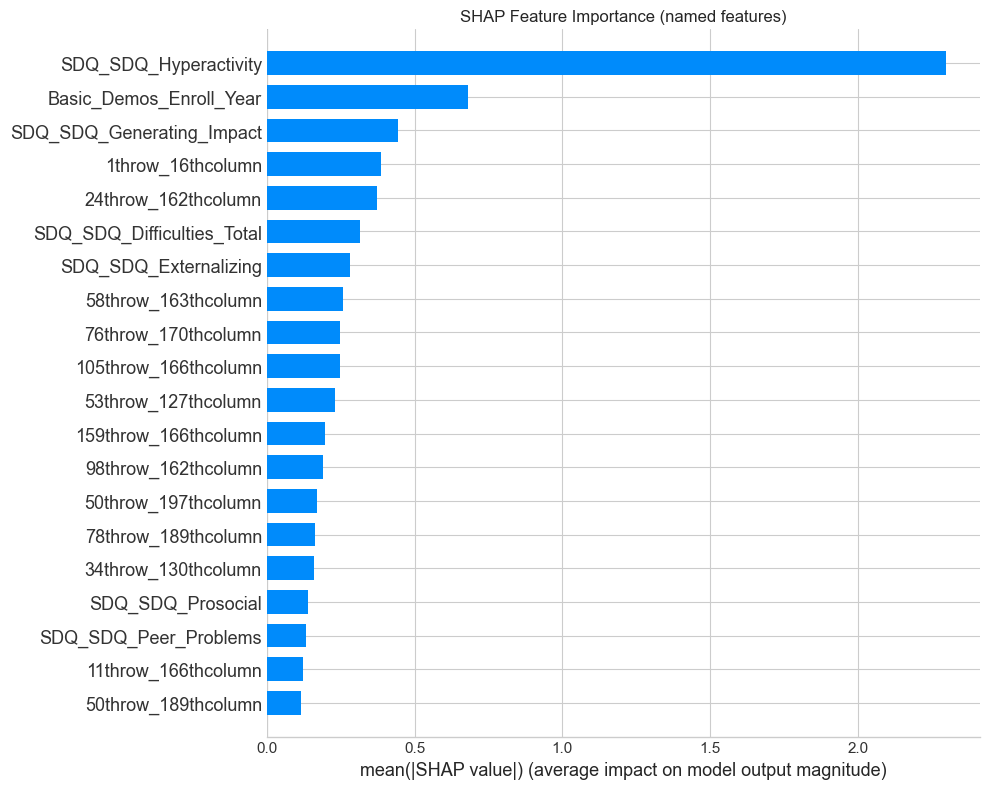

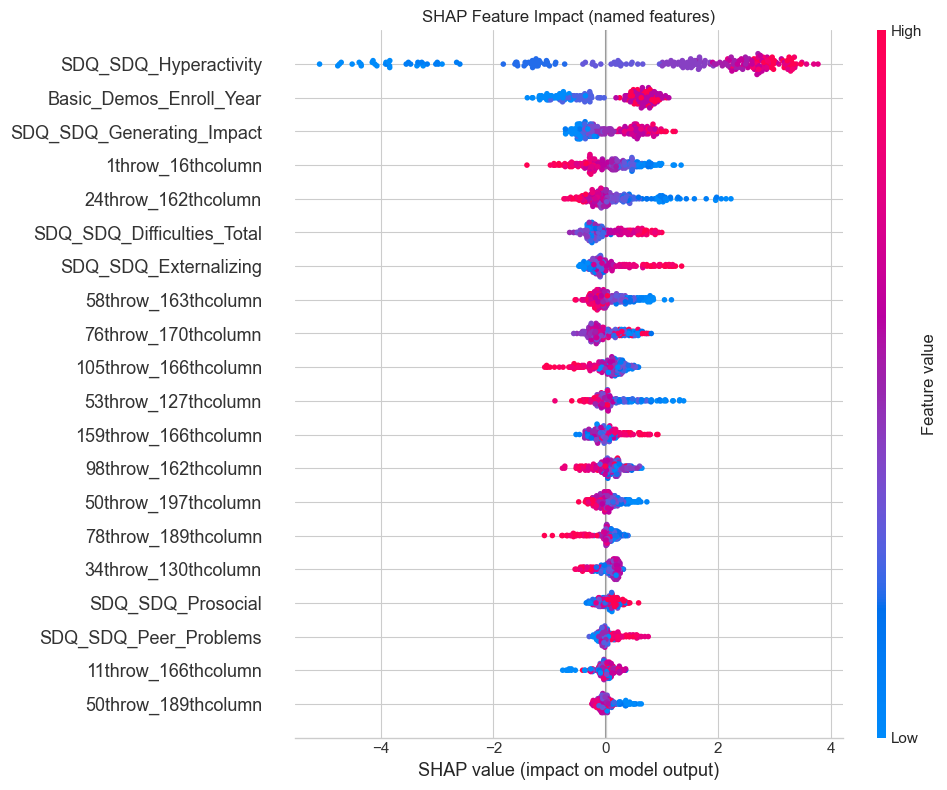


Top 10 features by mean |SHAP|:
   1. SDQ_SDQ_Hyperactivity               2.2985
   2. Basic_Demos_Enroll_Year             0.6794
   3. SDQ_SDQ_Generating_Impact           0.4424
   4. 1throw_16thcolumn                   0.3860
   5. 24throw_162thcolumn                 0.3714
   6. SDQ_SDQ_Difficulties_Total          0.3156
   7. SDQ_SDQ_Externalizing               0.2822
   8. 58throw_163thcolumn                 0.2575
   9. 76throw_170thcolumn                 0.2473
  10. 105throw_166thcolumn                0.2463


In [20]:

import os, numpy as np, matplotlib.pyplot as plt, shap
from sklearn.model_selection import train_test_split
os.makedirs('Shap_plot', exist_ok=True)

# 1) Split the NAMED (pre-PCA) features — 'X' holds the selected named features
Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# 2) SMOTE on training split only (uses your own helper; skips safely if absent)
Xs_tr_bal, ys_tr_bal = apply_smote(Xs_tr, ys_tr)

# 3) Train an interpretable tree model on the named features
interp_model = LGBMClassifier(random_state=RANDOM_STATE,
                              class_weight='balanced', verbose=-1)
interp_model.fit(Xs_tr_bal, ys_tr_bal)
print(f"Interpretation model trained on {Xs_tr_bal.shape[1]} named features.")

# 4) SHAP values — with the 3-D array fix
explainer   = shap.TreeExplainer(interp_model)
shap_values = explainer.shap_values(Xs_te)
if isinstance(shap_values, list):            # old SHAP → list
    shap_values = shap_values[1]
elif getattr(shap_values, "ndim", 2) == 3:   # new SHAP → 3-D array  (THE FIX)
    shap_values = shap_values[:, :, 1]

feat_list = list(feat_names)

# 5) Importance bar — DO NOT pre-create a figure (that caused the blank plots)
shap.summary_plot(shap_values, Xs_te, feature_names=feat_list,
                  plot_type='bar', show=False)
plt.gcf().set_size_inches(10, 8)
plt.title('SHAP Feature Importance (named features)')
plt.tight_layout()
plt.savefig('plots/shap_importance_named.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# 6) Beeswarm — direction of effect
shap.summary_plot(shap_values, Xs_te, feature_names=feat_list, show=False)
plt.gcf().set_size_inches(10, 8)
plt.title('SHAP Feature Impact (named features)')
plt.tight_layout()
plt.savefig('plots/shap_impact_named.png', dpi=150, bbox_inches='tight')
plt.show(); plt.close()

# 7) Ranked top features for your Recommendations section
mean_abs = np.abs(shap_values).mean(axis=0)
print("\nTop 10 features by mean |SHAP|:")
for i, (f, v) in enumerate(sorted(zip(feat_list, mean_abs),
                                  key=lambda x: -x[1])[:10], 1):
    print(f"  {i:2d}. {f:35s} {v:.4f}")

In [21]:

clean_full = train_fe.copy()


num_cols = clean_full.select_dtypes(include=[np.number]).columns
cat_cols = clean_full.select_dtypes(exclude=[np.number]).columns

if len(num_cols) > 0:
    clean_full[num_cols] = SimpleImputer(strategy='median').fit_transform(clean_full[num_cols])
if len(cat_cols) > 0:
    clean_full[cat_cols] = SimpleImputer(strategy='most_frequent').fit_transform(clean_full[cat_cols])


if 'ADHD_Outcome' not in clean_full.columns:
    clean_full['ADHD_Outcome'] = y.values if hasattr(y, 'values') else y


clean_full.to_csv('cleaned_adhd_dataset.csv', index=False)
print(f"Full clean dataset saved: {clean_full.shape[0]} rows x {clean_full.shape[1]} columns")
print(f"File: cleaned_adhd_dataset.csv")
print(f"Missing values remaining: {int(clean_full.isnull().sum().sum())}")
clean_full.head()

Full clean dataset saved: 1213 rows x 19932 columns
File: cleaned_adhd_dataset.csv
Missing values remaining: 0


,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,195throw_198thcolumn,195throw_199thcolumn,196throw_197thcolumn,196throw_198thcolumn,196throw_199thcolumn,197throw_198thcolumn,197throw_199thcolumn,198throw_199thcolumn,data_source,cluster
0,00aIpNTbG5uh,2019.0,4.0,1.0,0.0,3.0,21.0,45.0,18.0,35.0,...,-0.280312,0.037560,0.423037,0.242453,0.336213,0.402338,0.327915,0.539032,train,0.0
1,00fV0OyyoLfw,2017.0,1.0,0.0,9.0,2.0,21.0,0.0,21.0,45.0,...,-0.332783,-0.332711,0.556939,0.475578,0.429196,0.457970,0.312571,0.595978,train,1.0
2,04X1eiS79T4B,2017.0,1.0,1.0,2.0,2.0,9.0,0.0,18.0,35.0,...,-0.002132,-0.175586,0.679183,0.290292,0.486680,0.255208,0.575017,0.605182,train,2.0
3,05ocQutkURd6,2018.0,1.0,3.0,8.0,2.0,18.0,10.0,18.0,0.0,...,-0.199576,-0.216457,0.519074,0.298586,0.415466,0.511607,0.361204,0.446613,train,1.0
4,06YUNBA9ZRLq,2018.0,1.0,0.0,1.0,2.0,12.0,0.0,18.0,35.0,...,-0.141012,-0.002865,0.515169,0.336139,0.316430,0.442230,0.177079,0.378278,train,2.0
